# 🧪 6. 에이전트 평가와 개선 (Evaluation & Harness Engineering)

지금까지 만든 에이전트는 데모 질문 몇 개에는 "잘 동작하는 것처럼" 보입니다. 하지만 기업 현장에 배포하려면 **어떤 질문에서 실패하는지 정량적으로 측정하고, 모델이 아닌 시스템(도구·인덱스·시맨틱 레이어·프롬프트)의 어느 계층을 고쳐야 하는지 구조적으로 찾아내는 업무 방식**이 필요합니다.

이번 실습에서는 원천 데이터로부터 **골든 데이터셋을 반자동 합성·검수**하는 방법부터, **실무 수준의 메트릭 설계(`Faithfulness` 2단계 체인 및 커스텀 채점기)**, **2계층 평가 하네스를 통한 병목 진단**, **도구 계약 개선 후 비회귀 검증(`compare_table`)**, 그리고 **런타임 크로스체크·HITL 승인 게이트·운영 플라이휠**까지 전 과정을 완주합니다.

---

### 🎯 학습 목표
1. 엔터프라이즈 데이터를 에이전트와 연결하는 시맨틱 계층 및 **평가 → 계층 귀속(Layer Attribution) → 하네스 수정 → 비회귀 검증** 워크플로우를 이해합니다.
2. 원천 규정·스키마로부터 **실패 유형별 골든 데이터셋 초안(Silver)을 합성하고 자동 검증(Critique)**하여 평가셋을 구축합니다.
3. **고정 불변 지표(`Faithfulness` 2단계 NLI)**와 **시스템 맞춤 지표(결정론적 코드 채점기 · G-Eval 이산 루브릭)**를 구분해 실무 수준으로 구현합니다.
4. 도구 호출 궤적에서 `neg-01` 과잉 탐색의 원인 계층을 찾아 **도구 반환 계약을 개선(`agent_v2`)**하고, 12문항 전체 재평가로 **개선 효과와 무회귀(Non-Regression)**를 증명합니다.
5. 실행 중 개입 장치(**판사 모델 크로스체크, HITL 승인 게이트**)와 운영 로그 환류 플라이휠의 적용 기준을 익힙니다.

### 🎓 학습 목차

| 파트 | 주제 | 핵심 내용 |
|:---:|:---|:---|
| **Step 0** | 환경 세팅 | 프로젝트 루트, 모델(`gemini-3.8-flash`), 판사 모델(`gpt-5.4-mini`) 초기화 |
| **Part 1** | 품질 개선 경로와 실무 워크플로우 | 평가 기반 시스템 개선 vs 런타임 자가 수정, 기업 데이터 연결과 계층 귀속 루프 |
| **Part 2** | 골든 데이터셋 설계와 구축 | 12문항 실패 분류 체계, Cold-Start 반자동 합성(`Evolution → Critique`) vs Warm-Start 로그 환류 |
| **Part 3** | 메트릭 엔지니어링과 2계층 채점기 | 불변 지표 vs 커스텀 지표, `Faithfulness` 2단계 NLI 체인, 코드/G-Eval 채점기, 2계층 하네스 |
| **Part 4** | 베이스라인 평가 | 12문항 정량 채점, 점수 vs 비용(호출 수) 산점도 분석 |
| **Part 5** | 실패 진단과 하네스 개선 루프 | `neg-01` 궤적 진단 → 도구 반환 계약 개선(`agent_v2`) → `compare_table` 비회귀 검증 |
| **Part 6** | 운영 관점과 데이터 플라이휠 | 런타임 크로스체크(`StopHook`), HITL 승인 게이트(`approve`/`edit`/`reject`), CI & 운영 환류 |
| **Part 7** | 정리 | 엔터프라이즈 평가·개선 루프 요약 및 심화 과제 |

## 🛠️ Step 0. 환경 세팅

프로젝트 루트 경로를 자동 감지하여 `sys.path`에 등록하고, 환경변수(`.env`)와 비동기 이벤트 루프(`nest_asyncio`)를 설정합니다.

In [1]:
import os
import sys
import warnings
import asyncio
import nest_asyncio
from dotenv import load_dotenv

warnings.filterwarnings("ignore", message=".*IProgress not found.*")

# 1. 프로젝트 루트 경로 자동 설정 (app/ 폴더가 있는 위치까지 상위 탐색)
project_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(project_root, "app")):
        break
    project_root = os.path.dirname(project_root)

os.chdir(project_root)
if project_root not in sys.path:
    sys.path.insert(0, project_root)

# 2. 환경변수 로드 (프로젝트 루트의 .env)
load_dotenv(os.path.join(project_root, ".env"), override=True)

print(f"✅ Working Directory: {os.getcwd()}")

# 3. 주피터 노트북 비동기 루프 중복 방지
nest_asyncio.apply()

# 4. 공통 유틸리티 및 모델 로드
from app.utils import init_chat_model, normalize_content
from app.eval.rag_eval import JUDGE_MODEL

llm = init_chat_model(model="gemini-3.8-flash", temperature=0.0)           # 평가 대상 에이전트
judge_llm = init_chat_model(model=JUDGE_MODEL, temperature=0.0)             # 채점기: 다른 계열 모델 (gpt-5.4-mini)

✅ Working Directory: /mnt/c/Users/hyoun/Desktop/working_project/working_on_dir/Agentic_RAG/instructor


---
## 🔁 Part 1. 품질을 올리는 두 경로와 엔터프라이즈 개선 워크플로우

### 1.1 평가 기반 시스템 개선 vs 실행 중 자가 수정 (Self-Correction)

에이전트의 품질을 올리는 길은 두 가지입니다. **오프라인 평가 결과를 보고 시스템 자체를 고치는 것**과, **실행 도중에 에이전트가 자기 답변을 고치는 것**입니다.
엄밀한 의미의 "Self-Correction(자가 수정)"은 뒤의 것, 즉 런타임에 일어나는 교정만을 가리킵니다.

| 구분 | 평가 기반 시스템 개선 (Offline Harness Loop) | 실행 중 자가 수정 (Runtime Self-Correction) |
|:---|:---|:---|
| **누가 고치나** | 엔지니어(팀)가 평가 리포트와 궤적을 보고 | 에이전트(또는 런타임 미들웨어)가 실행 중에 스스로 |
| **무엇을 고치나** | **시스템 자체** (도구 계약, 인덱스, 시맨틱 레이어, 프롬프트) | **이번 답변 하나** (재검색, 답변 재작성) |
| **비용** | 개발·배포 시점에 오프라인 평가 비용만 발생 | 매 사용자 요청마다 지연 시간(Latency)과 토큰 비용 추가 |
| **효과의 지속성** | 고친 내용이 이후 **모든 요청에 영구 적용** | 근본 결함이 남으면 다음 요청에서 같은 실패가 반복됨 |
| **이 노트북에서** | **Part 2 ~ Part 5** (골든셋 → 채점 → 진단 → 하네스 수정·재평가) | **Part 6** (판사 모델 크로스체크, HITL 승인 게이트) |

> 💡 **두 종류의 하네스(Harness):** 이 노트북에는 하네스가 두 번 등장합니다. **에이전트 하네스**는 모델을 둘러싼 도구·프롬프트·시맨틱 레이어·미들웨어이고, **평가 하네스**는 그 에이전트를 정량 채점하는 시험 장치입니다. 모델을 더 비싼 것으로 바꾸지 않아도, 평가 하네스로 결함을 찾아 에이전트 하네스를 고치면 품질과 속도가 동시에 오릅니다.

모델의 기본 추론 능력이 높아지면서 "검색 결과가 조금 부족할 때 검색어를 바꿔 다시 찾기"는 대부분 ReAct 루프 안에서 모델이 스스로 수행합니다. 따라서 엔지니어에게 훨씬 중요한 일은 **에이전트가 스스로 고칠 수 없는 도구 인터페이스와 데이터 계층의 결함을 찾아내는 평가 루프**를 만드는 것입니다.

```mermaid
flowchart LR
    G["📋 1. 골든 데이터셋<br/>(실패 유형별 문항·라벨)"] --> R["🤖 2. 에이전트 실행<br/>(답변 + 도구 궤적 수집)"]
    R --> S["⚖️ 3. 2계층 채점<br/>(과정 40% + 결과 60%)"]
    S --> D["🩺 4. 계층 귀속 진단<br/>(도구·인덱스·프롬프트 특정)"]
    D --> F["🔧 5. 하네스 수정<br/>(도구 계약·시맨틱 레이어)"]
    F -->|"전체 문항 재평가 (개선 확인 + 비회귀 검증)"| G
```

### 1.2 엔터프라이즈 데이터를 에이전트에 연결하고 개선하는 구조화된 업무 방식

기업 엔지니어가 사내 데이터를 Agentic RAG에 연결할 때 가장 흔히 겪는 실패는 **"문서는 청크로 잘라 벡터 DB에 넣고, DB는 원시 DDL만 물려준 뒤, 오답이 나올 때마다 시스템 프롬프트에 예외 규칙을 덧대는 것(Vibes-based Prompt Patching)"**입니다.

팔란티어(Palantir)의 FDE(Forward Deployed Engineer) 팀을 비롯해 엔터프라이즈 현장에서 검증된 AI 엔지니어링 조직들은 감에 의존한 프롬프트 수정 대신 **① 원천 사일로의 시맨틱 구조화 → ② 도구 계약(Tool Contract) 분리 → ③ 계층 귀속(Layer Attribution) 기반 개선**이라는 표준화된 업무 방식을 따릅니다. 우리가 1~5번 노트북에서 구축한 요소들이 바로 이 구조의 각 계층에 대응합니다.

```mermaid
flowchart TB
    subgraph Silos["🏢 1계층: 기업 원천 데이터 사일로 (Raw Silos)"]
        S1["비정형 사내 규정·백서<br/>(PDF / DOCX / MD)"]
        S2["정형 운영 데이터베이스<br/>(ERP SQLite / RDB)"]
        S3["조직·결재선·프로젝트<br/>(복합 다중 홉 관계)"]
    end

    subgraph Semantic["🧭 2계층: 시맨틱·온톨로지 정렬 계층 (Semantic & Ontology Layer)"]
        M1["표준 Markdown 정규화 + 문맥 헤더(TOC)<br/>+ DomainDictionary (약어 정규화)"]
        M2["semantic_layer.yaml (업무 정의·공식 지표)<br/>+ SchemaRetriever + ValueLinker"]
        M3["개체(Entity)·관계(Edge) 지식 그래프<br/>+ 커뮤니티 요약 리포트"]
    end

    subgraph Contracts["🧰 3계층: 에이전트 도구 계약 (Tool Contracts & Guardrails)"]
        T1["search_company_policy / search_aws_guides<br/>(출처 경로 + 미존재 신호 반환)"]
        T2["search_enterprise_erp<br/>(읽기 전용 2중 가드레일 + 되묻기 신호)"]
        T3["graph_* 탐색 도구 5종<br/>(엔티티 → 이웃 → 원문 점진 탐색)"]
    end

    S1 --> M1 --> T1
    S2 --> M2 --> T2
    S3 --> M3 --> T3
```

| 엔지니어링 단계 | 핵심 실무 원칙 | 우리 시스템의 구현 위치 |
|:---|:---|:---|
| **① 시맨틱 계층 연결** | 원천 데이터를 모델에 날것으로 노출하지 않고, **사내 용어 사전·업무 지표 공식·개체 관계**를 중간 의미 계층에 명시 | `DomainDictionary`, `semantic_layer.yaml`, `HybridRetriever` 문맥 헤더 |
| **② 도구 계약 설계** | 모델은 함수 코드를 보지 못하고 **이름·Docstring·반환 문자열**만 보므로, 선택 경계와 "결과 없음/되묻기" 신호를 도구 계약에 정의 | `app/agents/tool_rag_agent/tools.py`, `rag/sql/text2sql_agent.py` |
| **③ 초기 골든셋 고정** | 현업 담당자(SME)에게 백지 엑셀을 주는 대신, 엔지니어가 원천 데이터로 **초안(Silver)을 합성**하고 SME는 **O/X 및 한 줄 규칙만 검수(Gold)** | **Part 2.2** 반자동 합성·검증 파이프라인 |
| **④ 계층 귀속(Layer Attribution)** | 평가 실패 시 프롬프트만 고치지 않고, 궤적을 통해 **어느 계층(도구 설명 / 반환 형식 / 인덱스 / 시맨틱 레이어 / 라벨)의 책임인지 분리** | **Part 3 ~ Part 5.1** 2계층 채점 및 궤적 진단 |
| **⑤ 비회귀 게이트(CI Gate)** | 결함 수정 후 해당 문항만 확인하지 않고 **전체 골든셋을 재채점**해 기존 통과 문항의 회귀(`NOISE_BAND` 초과 하락)가 없을 때만 반영 | **Part 5.2** `compare_table(rows, rows_v2)` |

---
## 📋 Part 2. 골든 데이터셋: 설계 원칙과 반자동 구축 파이프라인

### 2.1 실패 유형별 골든 데이터셋 해부 (12문항)

좋은 골든셋은 "쉬운 FAQ 모음"이 아니라 **에이전트가 현장에서 실패할 수 있는 방식(Failure Mode)마다 최소 1문항 이상을 의도적으로 배치한 회귀 시험지**입니다.
이번 실습의 기본 골든셋 12문항(`data/eval/golden_eval_dataset.json`)은 **4대 데이터 소스(사내 규정 · AWS 백서 · 지식 그래프 · ERP Text2SQL)**가 모두 검증되도록 설계되어 있으며, 과정과 결과를 분리 채점하기 위해 두 가지 정답 라벨을 갖습니다.

| 라벨 | 채점에 쓰이는 곳 |
|:---|:---|
| **정답 (`ground_truth`)** | 답변의 핵심 사실·수치·결론이 맞는가(**정답 일치**), 정답 도출에 필요한 근거를 빠짐없이 가져왔는가(**검색 재현**) |
| **써야 하는 도구 (`target_tools`)** | 질문 의도에 맞는 도구를 골랐는가(**도구 선택**) |

> 💡 **공정한 라벨링 원칙 (`"A | B"` 동치 표기):** 프로젝트 PM·승인권자·의존 관계처럼 **같은 정보가 지식 그래프와 ERP `projects` 테이블 양쪽에 모두 존재하는 경우**, 정답 도구를 `["graph_* 탐색 도구(...) | search_enterprise_erp"]`처럼 `|`로 묶어 둡니다. 하나만 적어 두면 에이전트가 다른 정상 경로로 정확한 답을 찾아도 "도구 선택 미달"로 오진하는 **채점 라벨 결함**이 발생합니다.

In [2]:
import pandas as pd
from IPython.display import display
from app.eval.rag_eval import load_golden

golden = load_golden()
golden_df = pd.DataFrame(golden)[["id", "category", "question", "ground_truth", "target_tools"]]
golden_df.columns = ["문항", "유형", "질문", "정답 (ground_truth)", "써야 하는 도구"]
display(golden_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

문항,유형,질문,정답 (ground_truth),써야 하는 도구
pol-01,단일 규정,팀원이 당일 출장을 가면 일비와 식비는 얼마를 받나요?,"국내 여비 및 교통비 지급 규정 제15조 제2항에 따라 당일 출장 시 일비는 기준액의 50%, 식비는 1식(12,000원)을 지급한다. 팀원(선임/전임)의 일비 기준액은 25,000원이므로 일비 12,500원과 식비 12,000원을 받는다.",['search_company_policy']
pol-02,약어 + 복수 조항,"클운팀 직원이 출장을 가면 결재는 누가 최종 승인하고, 정산은 언제까지 해야 하나요?",제21조에 따라 클라우드운영팀(클운팀)은 팀원 출장 시 팀장 승인 후 클라우드사업본부장이 전결한다. 제20조에 따라 출장 종료일로부터 7영업일 이내에 사내 ERP의 '여비교통비 정산 신청' 메뉴로 영수증을 첨부해 결재를 상신해야 한다.,['search_company_policy']
pol-03,표 데이터 + 계산,서울 출장 시 팀장과 팀원의 1박 숙박비 한도 차이는 얼마인가요?,"제14조 표에 따라 서울 및 수도권 1박 숙박비 상한은 팀장(수석/책임) 130,000원, 팀원(선임/전임) 100,000원이므로 차이는 30,000원이다.",['search_company_policy']
sec-01,복수 조항,"고객사 납품용 소스코드를 사외로 반출하려면 어떤 승인을 받아야 하고, 위반하면 어떻게 되나요?","정보보안 관리 지침 제14조에 따라 DLP 결재 시스템으로 사전 신청하고 1차 소속 팀장, 2차 CISO(정보보안책임자)의 승인을 받아야 한다. 제15조에 따라 위반으로 정보가 유출되면 인사위원회에 회부되어 사규 제45조에 따라 경고, 감봉, 정직 또는 징계해고에 처할 수 있고 민형사상 손해배상 책임을 질 수 있다.",['search_company_policy']
org-01,다중 홉 관계,김철수 수석이 총괄하는 프로젝트의 예산을 최종 승인하는 사람은 누구인가요?,"김철수 수석(클라우드운영팀 팀장)은 P-01 클라우드 네이티브 마이그레이션의 총괄 PM이다. 예산은 3억 5,000만원으로 5,000만원 이상 5억원 미만 구간이므로 소속 본부장이 최종 승인하며, 승인권자는 클라우드사업본부장 박영희 전무다.",['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp']
org-02,다중 홉 관계,P-02 Agentic RAG 플랫폼 프로젝트의 일정에 영향을 줄 수 있는 의존 관계는 무엇인가요?,"P-02(엔터프라이즈 Agentic RAG 플랫폼 구축, 총괄 PM 홍팀장)의 일정은 선행 프로젝트 네 개에 걸려 있다. ① P-01 클라우드 네이티브 마이그레이션의 하이브리드 K8s 인프라 구축 완료가 선행 필수이고, ② P-05 멀티클라우드 GPU 추론 클러스터 고도화의 vLLM 서빙 노드 할당이 선행 필수이며, ③ P-03 차세대 AI 데이터 거버넌스의 Query-Time ACL 필터와 ④ P-04 금융권 생성형 AI 보안 가드레일의 입출력 마스킹 모듈을 출시 전에 통합해야 한다. 또한 클라우드운영팀에서 최책임 책임엔지니어를 파견받아 협업하고 있어 인력 의존도 있다. (P-06과의 관계, 정보보안팀 레드팀 감사 등을 추가로 언급하는 것은 무방하다.)",['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp']
aws-01,동일 소스 다회 검색,AWS Well-Architected 프레임워크에서 성능 효율성 영역과 비용 최적화 영역의 설계 원칙을 비교해줘.,"성능 효율성(Performance Efficiency) 백서의 설계 원칙은 ① 고급 기술의 대중화(Democratize advanced technologies), ② 몇 분 만에 글로벌 배포(Go global in minutes), ③ 서버리스 아키텍처 사용(Use serverless architectures), ④ 더 자주 실험(Experiment more often), ⑤ 기계적 공감 고려(Consider mechanical sympathy)의 5가지다. 비용 최적화(Cost Optimization) 백서의 설계 원칙은 ① 클라우드 재무 관리 구현(Implement cloud financial management), ② 소비 모델 채택(Adopt a consumption model), ③ 전체 효율성 측정(Measure overall efficiency), ④ 차별화되지 않는 과중한 작업에 대한 지출 중단(Stop spending money on undifferentiated heavy lifting), ⑤ 지출 분석 및 귀속(Analyze and attribute expenditure)의 5가지다. 두 영역의 원칙을 서로 바꾸어 답하거나 다른 영역(보안·신뢰성)의 원칙을 섞으면 오답이다.",['search_aws_guides']
erp-01,정형 데이터 집계,"승인완료된 지출 기준으로 예산 집행률이 80%를 넘은 전략 프로젝트는 어디이고, 집행률은 각각 몇 %인가요?","ERP의 프로젝트 승인 예산 대비 '승인완료' 지출 전표 합계로 계산하면 두 프로젝트가 80%를 넘는다. P-02 엔터프라이즈 Agentic RAG 플랫폼 구축은 승인 예산 480,000,000원 중 412,800,000원을 집행해 86.0%이고, P-05 멀티클라우드 GPU 추론 클러스터 고도화는 620,000,000원 중 527,000,000원을 집행해 85.0%다.",['search_enterprise_erp']
mix-01,이종 소스 결합 (그래프 + 규정),AgenticAI팀 홍팀장이 대구로 2박 3일 출장을 가면 숙박비 한도와 일비 총액은 얼마인가요?,"홍팀장은 AgenticAI팀 팀장(수석)으로 팀장(수석/책임) 기준이 적용된다. 대구는 광역시이므로 제14조에 따라 1박 숙박비 상한 100,000원(2박 최대 200,000원), 제15조에 따라 일비 1일 30,000원 × 3일 = 90,000원이다.","['graph_* 탐색 도구(graph_find_entities → graph_neighbors) | search_enterprise_erp', 'search_company_policy']"
cross-01,이종 소스 결합 (규정 + ERP),"국내 여비 규정의 숙박비 한도를 기준으로, ERP에서 결재대기 중인 국내출장 품의 가운데 1박당 숙박비 한도를 초과한 건을 모두 찾아줘.","국내 여비 및 교통비 지급 규정 제14조의 1박 상한은 팀장(수석/책임) 서울 130,000원·광역시 100,000원, 팀원(선임/전임) 서울 100,000원·광역시 80,000원이다. 이 기준으로 결재대기 국내출장 품의를 대조하면 3건이 초과한다. ① TX-2026-0131 이선임(선임): 서울 1박 150,000원 청구, 상한 100,000원 대비 50,000원 초과. ② TX-2026-0132 윤에이전트(책임): 부산 2박 280,000원(1박 140,000원) 청구, 상한 100,000원 대비 1박당 40,000원(총 80,000원) 초과. ③ TX-2026-0133 장LLM(선임): 대전 1박 120,000원 청구, 상한 80,000원 대비 40,000원 초과. 나머지 결재대기 국내출장 품의(TX-2026-0119, 0121, 0125)는 한도 이내다.","['search_company_policy', 'search_enterprise_erp']"


| 범주 | 문항 | 확인하려는 실패 |
|:---|:---|:---|
| 단일 규정 / 복수 조항 / 표 데이터 | `pol-01~03`, `sec-01` | 하이브리드 검색 품질, 마크다운 표 행·열 수치 계산 왜곡 |
| 약어 / 용어 불일치 | `pol-02`, `term-01` | 현업 약어(`클운팀`) 및 사규 미정의 직급(`과장급`) 대응 |
| 다중 홉 관계 | `org-01`, `org-02` | 엔티티 탐색 후 이웃 관계를 따라가는 다단계 추론 |
| 동일 소스 다회 검색 | `aws-01` | 하위 질의 분해, 영문 백서 내 동명 섹션(`Design principles`) 혼동 방지 |
| 정형 데이터 집계 | `erp-01` | 시맨틱 레이어 지표 공식(`승인완료` 필터) 및 SQL 집계 정확도 |
| 이종 소스 결합 | `mix-01` (그래프+규정), `cross-01` (규정+ERP) | 앞 도구가 찾은 규정 상한액을 다음 도구(`context`)의 감사 조건으로 전달하는가 |
| 존재하지 않는 정보 | `neg-01` | 환각 억제 및 **없는 제도를 확인하기까지 과잉 탐색 없이 멈추는가** |

### 2.2 실무 골든셋 구축: Cold-Start 합성·검증과 Warm-Start 로그 환류

현업 엔지니어들이 가장 많이 묻는 질문은 **"처음 시스템을 오픈하기 전, 아직 사용자 로그가 하나도 없을 때 골든 데이터셋은 어떻게 만드나요?"**입니다. 실무에서는 **배포 시점(Day 0 vs Day 2+)**과 **목적(취약점 탐색 vs 회귀 검증)**에 따라 도구를 명확히 구분해 운영합니다.

#### ① 동적 레드팀 봇(Dynamic Red-Teaming) vs 정적 골든 벤치마크(Static Golden Set)

| 구분 | 동적 레드팀 / 시뮬레이션 봇 | 정적 골든 데이터셋 (이 노트북의 초점) |
|:---|:---|:---|
| **작동 방식** | 공격·페르소나 봇이 에이전트와 멀티턴으로 대화하며 약점을 실시간 추궁 | 고정된 `(question, ground_truth, target_tools)` 쌍을 동일 조건으로 일괄 실행 |
| **주 목적** | 미지의 엣지 케이스·탈옥·논리 허점 **발굴 (Discovery)** | 코드·프롬프트 변경 전후 **점수·호출 수 비회귀 비교 (Regression Gate)** |
| **관계** | 레드팀 봇이 찾아낸 실패 대화 중 재현 가치가 높은 건을 정제해 **정적 골든셋 문항으로 편입** | 매 배포(CI)마다 실행되는 기준선 역할 |

#### ② Day 0 (Cold-Start 합성) vs Day 2+ (Warm-Start 로깅 도구 추출)
- **Day 2+ (운영 시작 후 — Warm-Start):** `LangSmith`, `Langfuse` 같은 LLMOps 관측 도구에 쌓인 실제 사용자 트레이스 중 **👎 피드백, 낮은 온라인 채점 점수, HITL 반려(`reject`/`edit`) 케이스**를 필터링해 `Add to Dataset`으로 추출한 뒤 정답만 보정합니다. 가장 가치 높은 문항 공급원입니다.
- **Day 0 (배포 전 — Cold-Start 반자동 합성):** 운영 로그가 없으므로 **원천 문서와 DB 시맨틱 레이어**에서 문항을 합성해야 합니다. 단, LLM에게 *"문제 10개 만들어줘"*라고 단순 지시하면 원문 표현을 그대로 베낀 쉬운 단답형이나 *"위 표에 따르면..."*처럼 문맥 없이는 풀 수 없는 불량 문항이 생성됩니다.

RAGAS(`TestsetGenerator`의 Evol-Instruct)와 DeepEval(`Synthesizer`) 등 실무 프레임워크의 핵심 원리를 압축하면 아래 **2단계 합성·검증(`Evolution Synthesizer → Critique Verifier`) + SME Triage** 파이프라인이 됩니다.

```mermaid
flowchart LR
    Src["📄 원천 규정 청크<br/>+ semantic_layer.yaml"] --> Syn["🧬 Step 1. Evolution 합성기<br/>· 실패 유형별 조건·제약 부여<br/>· 지시어 제거(자립형 질문화)"]
    Syn --> Crit["🔍 Step 2. Critique 자동 검증기<br/>· 원문 근거 일치(Grounded)<br/>· 문맥 독립성(Standalone)<br/>· 단일 결론 명확성(Unambiguous)"]
    Crit -->|"통과 (Silver 후보)"| SME["👤 Step 3. 현업 SME 검수<br/>백지 작성 대신 O/X 판정과<br/>한 줄 도메인 규칙만 코멘트"]
    Crit -->|"미달"| Drop["🗑️ 폐기 또는 재생성"]
    SME --> Gold["🏆 golden_eval_dataset.json"]
```

아래 셀에서 실제 사내 여비 규정(`2026_국내여비교통비지급규정.md`)과 ERP 시맨틱 레이어(`semantic_layer.yaml`)를 입력으로 넣어 **4가지 핵심 실패 유형의 Silver 문항을 합성하고, 판사 모델(`judge_llm`)로 자동 품질 검수**까지 수행해 봅니다.

In [3]:
import json
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate


class SilverCandidate(BaseModel):
    category: Literal["표 데이터 + 계산", "용어 불일치", "이종 소스 결합 (규정 + ERP)", "존재하지 않는 정보"] = Field(
        description="검증하려는 실패 유형"
    )
    question: str = Field(
        description="임직원이 메신저에 묻듯 작성한 자립형 질문 ('위 조항에 따르면', '동 지침상' 등 원문 지시어 절대 금지)"
    )
    ground_truth: str = Field(
        description="채점 기준이 되는 완결된 정답 (관련 조항 번호, 계산식/수치, 비공식 호칭일 경우 가능한 직급 구간별 금액과 확인 절차 명시)"
    )
    evidence_quote: str = Field(
        description="정답의 근거가 되는 원문 핵심 구절 인용 (존재하지 않는 정보 유형은 확인한 문서 범위 기재)"
    )
    target_tools: list[str] = Field(description="호출해야 하는 정답 도구 목록 (대체 가능 도구는 'A | B' 표기)")


class SilverBatch(BaseModel):
    candidates: list[SilverCandidate] = Field(description="실패 유형별 합성 문항 4건")


class CritiqueVerdict(BaseModel):
    is_grounded: bool = Field(description="정답의 모든 수치·조건이 제공된 원문/스키마와 정확히 일치하며 추측이 없는가")
    is_standalone: bool = Field(description="원문을 보지 않은 상태에서 질문만 읽어도 대상·조건이 자립적으로 명확한가")
    is_unambiguous: bool = Field(description="채점 기준(단일 수치 결론, 미존재 안내, 또는 비공식 직급의 후보 구간 병기)이 명확한가")
    reason: str = Field(description="한 줄 검증 사유 및 현업 SME 확인 포인트")


SYNTH_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "당신은 엔터프라이즈 Agentic RAG 평가셋을 설계하는 시니어 엔지니어입니다.\n"
     "제공된 [원천 데이터]만을 근거로 4가지 실패 유형을 각각 1문항씩(총 4문항) 합성하세요.\n"
     "1. 자립성(Decontextualization): 질문에 '위 표에서', '제14조에 따르면' 같은 문서 의존 지시어를 절대 쓰지 마세요.\n"
     "2. 현장 어휘: 실제 직원이 질문하듯 구체적 상황(직급, 출장 도시, 박수, 비공식 호칭 등)을 담으세요.\n"
     "3. 실패 유형별 설계 지침:\n"
     "   - '표 데이터 + 계산': 직급·지역·일수 조건을 걸어 숙박비·일비·식비 표 수치를 조합·합산해야 하는 질문\n"
     "   - '용어 불일치': 공식 직급(수석/책임/선임/전임) 대신 '차장급' 등 비공식 호칭을 쓰고, 정답에는 가능한 직급 구간별 금액과 인사기획팀 매핑 확인 절차를 모두 명시\n"
     "   - '이종 소스 결합 (규정 + ERP)': 여비 규정의 상한액을 먼저 찾고 ERP 지출 전표(expense_transactions)와 대조해야 하는 감사 질문\n"
     "   - '존재하지 않는 정보': 출장·복리후생과 그럴듯하게 연관되지만 원문에 전혀 없는 제도를 묻는 Hard Negative 질문\n"
     "4. 도구 이름: 'search_company_policy', 'search_enterprise_erp' 중 필요한 도구를 정확히 지정하세요."),
    ("human", "[원천 데이터]\n{source_bundle}"),
])

CRITIQUE_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "당신은 골든 데이터셋 품질 검수자(Critique Agent)입니다. 합성된 문항이 [원천 데이터]에 엄격히 부합하는지 검증하세요.\n"
     "- '존재하지 않는 정보' 유형은 원문에 해당 제도가 실제로 없고 ground_truth가 미존재를 안내하면 is_grounded=True입니다.\n"
     "- '용어 불일치' 유형은 비공식 호칭임을 밝히고 후보 직급별 금액 및 매핑 절차를 안내하도록 ground_truth가 작성되었으면 is_unambiguous=True입니다."),
    ("human", "[원천 데이터]\n{source_bundle}\n\n[합성 문항]\n{candidate}"),
])

with open("data/policies/2026_국내여비교통비지급규정.md", encoding="utf-8") as f:
    policy_raw = f.read()
policy_slice = policy_raw[policy_raw.find("제14조"):policy_raw.find("제14조") + 3500]
with open("data/enterprise_erp_sql/semantic_layer.yaml", encoding="utf-8") as f:
    erp_slice = f.read()[:2200]

source_bundle = f"[사내 규정: 2026_국내여비교통비지급규정.md 발췌]\n{policy_slice}\n\n[ERP 시맨틱 레이어 발췌]\n{erp_slice}"

# Step 1: 원천 데이터로부터 실패 유형별 Silver 후보 4건 자동 합성
silver_batch = await (SYNTH_PROMPT | llm.with_structured_output(SilverBatch)).ainvoke({"source_bundle": source_bundle})

# Step 2: 다른 계열 판사 모델(judge_llm)로 근거 일치·자립성·명확성 자동 검증
critique_chain = CRITIQUE_PROMPT | judge_llm.with_structured_output(CritiqueVerdict)
verified_rows, gold_ready_items = [], []

for idx, cand in enumerate(silver_batch.candidates, 1):
    verdict = await critique_chain.ainvoke({
        "source_bundle": source_bundle,
        "candidate": json.dumps(cand.model_dump(), ensure_ascii=False, indent=2),
    })
    passed = verdict.is_grounded and verdict.is_standalone and verdict.is_unambiguous
    verified_rows.append({
        "후보 ID": f"syn-{idx:02d}",
        "실패 유형": cand.category,
        "합성된 질문 (Question)": cand.question,
        "써야 하는 도구": cand.target_tools,
        "Critique 판정": "✅ 통과 (SME 검수 대기)" if passed else "⚠️ 보완 필요",
        "검증 사유": verdict.reason,
    })
    if passed:
        gold_ready_items.append({
            "id": f"syn-{idx:02d}",
            "category": cand.category,
            "question": cand.question,
            "ground_truth": cand.ground_truth,
            "target_tools": cand.target_tools,
        })

display(pd.DataFrame(verified_rows).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
print(f"\n🏆 Critique 자동 검증 통과: {len(gold_ready_items)}/{len(silver_batch.candidates)}건 → SME 승인 후 golden_eval_dataset.json 스키마로 즉시 편입 가능")

후보 ID,실패 유형,합성된 질문 (Question),써야 하는 도구,Critique 판정,검증 사유
syn-01,표 데이터 + 계산,"이번에 선임 연구원 1명이 부산으로 2박 3일 국내 출장을 다녀올 예정인데, 숙박비 상한액 실비 전액과 일비, 식비를 모두 합치면 여비로 최대 얼마까지 지원받을 수 있나요? (식사는 따로 제공받지 않는 조건입니다)",['search_company_policy'],✅ 통과 (SME 검수 대기),"문항의 부산은 제14조의 '광역시 및 특례시'에 해당하고, 선임 연구원은 규정상 '팀원(선임/전임)'으로 해석되므로 2박 3일 기준 숙박비 160,000원(80,000원×2), 일비 75,000원(25,000원×3), 식비 105,000원(35,000원×3) 합계 340,000원 산출이 원문과 일치합니다. 질문 자체만으로 대상 직급·출장지·기간·식사 미제공 조건이 모두 명확해 독립적으로 해석 가능하며, 직급 표기 또한 팀원(선임/전임) 매핑이 규정에 제시되어 있어 모호하지 않습니다."
syn-02,용어 불일치,외부에서 파견 오신 차장급 인력이 대구로 1박 2일 출장을 갈 때 숙박비는 1박에 얼마까지 실비 정산이 가능한가요?,['search_company_policy'],✅ 통과 (SME 검수 대기),"원문 제15조 제4항에 ‘차장’은 공식 직급이 아니므로 인사기획팀 매핑이 필요하다고 명시되어 있고, 매핑 후 적용 가능한 후보 직급과 금액(팀장 100,000원, 팀원 80,000원)도 제14조 표와 정확히 일치합니다. 질문은 대구 1박 숙박비 한도를 묻는 것으로 대상(외부 파견 차장급 인력)·조건(대구, 1박 2일)이 명확하며, 답변도 공식 직급 미정의와 후보별 금액 및 절차를 함께 제시해 단일 수치가 아니라는 점이 분명합니다."
syn-03,이종 소스 결합 (규정 + ERP),최근 서울 출장을 다녀온 책임 직급 직원이 올린 숙박비 결재 신청 건 중 규정상 숙박비 상한액을 초과하여 결재 승인 완료된 지출 전표 내역이 있는지 감사 차원에서 확인해 주세요.,"['search_company_policy', 'search_enterprise_erp']",⚠️ 보완 필요,"원문과의 불일치가 있습니다. 제14조 기준으로 팀장(수석/책임)의 서울 및 수도권 숙박비 상한은 130,000원이 맞지만, 합성 문항은 이를 ‘책임 직급 직원’으로만 지칭해 ERP의 rank 값과의 매핑이 원문상 명시되지 않았습니다(사규에는 ‘책임’이 팀장 구분의 괄호표기일 뿐, DB 컬럼 값과의 대응은 인사기획팀 확인이 필요). 또한 질문은 ‘최근 서울 출장을 다녀온’이라고 했지만, ground_truth는 최근/기간 조건을 반영하지 않고 단순 조회로 안내하고 있습니다. 따라서 금액 자체는 맞지만, 질문에 포함된 대상/조건을 엄밀히 만족하는 정답 안내로 보기 어렵습니다."
syn-04,존재하지 않는 정보,"이번에 3박 4일 일정으로 지방 장기 출장을 가게 되었는데, 사내 규정상 장기 출장자에게 제공되는 주말 귀가 교통비 지원이나 출장 세탁비 지원비 지급 기준이 어떻게 되나요?",['search_company_policy'],✅ 통과 (SME 검수 대기),"원문 규정의 제14~21조 어디에도 주말 귀가 교통비나 출장 세탁비 지급 조항이 없고, ground_truth도 해당 제도가 존재하지 않음을 명시해 원천 문서에 부합합니다. 질문만 읽어도 장기 출장자 지원 제도 자체를 묻는 것으로 대상과 조건이 자립적으로 명확하며, 존재하지 않는 정보라는 점과 지급 불가 결론도 단일하게 해석됩니다."



🏆 Critique 자동 검증 통과: 3/4건 → SME 승인 후 golden_eval_dataset.json 스키마로 즉시 편입 가능


---
## ⚖️ Part 3. 메트릭 엔지니어링과 2계층 채점 하네스

### 3.1 엔지니어를 위한 메트릭 분류: 무엇을 가져다 쓰고, 무엇을 직접 정의할까?

기업 엔지니어들이 평가 체계를 설계할 때 자주 겪는 혼란은 *"RAGAS나 학술 벤치마크 지표를 그대로 써야 하나요, 아니면 전부 새로 만들어야 하나요?"*입니다. 정답은 **시스템이 바뀌어도 변하지 않는 보편 지표(Invariants)는 표준 패턴을 가져다 쓰고, 사내 데이터 구조·업무 정책에 종속된 지표는 엔지니어가 직접 정의**하는 것입니다.

| 구분 | 대표 메트릭 | 무엇을 측정하는가 | 채택·구현 전략 |
|:---|:---|:---|:---|
| **① 보편 불변 지표**<br/>*(Universal Invariants)* | `Faithfulness` (근거 충실도)<br/>`Context Recall / Precision`<br/>`Latency`, `Tool Call Count` | 검색 문맥 외 지어냄(환각) 여부, 근거 회수율, 응답 지연·호출 비용 | 도메인과 무관하게 정의가 동일함.<br/>**검증된 2단계 분해·검증 패턴**을 고정 사용 |
| **② 라벨 주입형 지표**<br/>*(Parameterized Metrics)* | `Answer Correctness` (정답 일치)<br/>`Tool Selection` (`"A \| B"` 허용) | 사내 정답 사실·수치와의 일치도, 아키텍처 의도에 맞는 도구 선택 | 채점 로직은 고정하되, **Part 2에서 구축한 사내 골든 라벨**을 주입해 평가 |
| **③ 시스템 맞춤 지표**<br/>*(Custom Policy Metrics)* | 조항·전표 번호 인용 준수율<br/>호출 예산(Step Budget) 준수<br/>미정의 직급(`과장급`) 대응 정책 | 사내 감사 추적성(Citation), 운영 비용 상한, 모호한 질문 시 추측 금지 원칙 | **1순위: 결정론적 Python 코드 채점기**<br/>**2순위: G-Eval 이산 앵커(0/1/2) 루브릭** |

> 📌 **실무 메트릭 설계의 제1원칙: "코드로 짤 수 있으면 절대 LLM 판사를 쓰지 마라."**
> 출처 조항(`제14조`, `TX-2026-...`) 포함 여부, 도구 호출 횟수 상한, 금지어 포함 여부, SQL/JSON 문법 유효성은 정규표현식과 파이썬 코드 몇 줄이면 **비용 0원, 지연 0ms, 재현성 100%**로 채점됩니다. LLM-as-a-Judge는 의미적 동치나 정책 준수처럼 코드로 판별할 수 없는 영역에만 아껴 씁니다.

### 3.2 [실습] 실무 수준 메트릭 직접 구현하기

AI 코딩 도구나 입문 예제에서 흔히 보는 `"다음 답변의 충실도를 0.0~1.0 사이로 채점해줘"` 같은 단일 프롬프트는 실행할 때마다 점수가 널뛰고, 유창한 문체에 속아 교묘한 수치 왜곡을 놓치기 때문에 실무 품질 게이트로 쓸 수 없습니다.

RAGAS, DeepEval 등 프로덕션 평가 프레임워크의 내부 구조를 바탕으로, 외부 무거운 라이브러리 의존성 없이 **실무에 바로 투입할 수 있는 두 가지 핵심 평가 체인**을 구현해 봅니다.

#### ① 보편 지표: `Faithfulness` 2단계 분해·검증 체인 (`ClaimExtractor` → `Query-Isolated NLI`)
실무형 `Faithfulness` 체인이 단일 프롬프트와 결정적으로 다른 세 가지 설계 포인트에 주목하세요.
1. **원자적 주장 분해 (`ClaimExtractor`)**: 긴 답변을 대명사가 해소된 단일 사실 문장(`claims`)으로 쪼개고 인사말을 제거합니다.
2. **질문 격리 검증 (`Query-Isolated NLI`)**: 2단계 검증 프롬프트에는 **의도적으로 사용자 질문(`user_query`)을 빼고 `contexts`와 `claims`만 전달**합니다. 질문을 함께 보여주면 판사 LLM이 검색 문맥이 아닌 자기 사전 지식으로 "맞는 말"이라고 통과시키는 편향이 생기기 때문입니다.
3. **3분류 판정(`yes`/`no`/`idk`) + 미존재 응답(`is_abstention`) 보호**: 각 주장을 `yes / no / idk`로 판정한 뒤 파이썬에서 $\frac{\#\text{yes}}{\#\text{yes} + \#\text{no}}$를 계산하며, `neg-01`처럼 *"규정에서 확인되지 않는다"*고 바르게 답한 경우 분모가 0이 되어 0점 처리되는 고전적 버그를 막습니다.

In [4]:
class ExtractedClaims(BaseModel):
    is_abstention: bool = Field(
        description="답변의 핵심 결론이 '문서/시스템에서 확인되지 않는다(정보 없음)'는 정당한 미존재 안내인지 여부"
    )
    claims: list[str] = Field(
        description="답변에서 추출한 대명사 해소된 원자적 사실 주장(atomic factual claims) 목록. 인사말·형식적 안내문은 제외"
    )


class ClaimVerdict(BaseModel):
    claim: str = Field(description="검증 대상 단일 사실 주장")
    evidence: str = Field(description="검색 문맥 내 관련 근거 요약 또는 불일치/부재 사유 (1문장)")
    verdict: Literal["yes", "no", "idk"] = Field(
        description="문맥으로 뒷받침되면 'yes', 문맥과 충돌하거나 문맥에 없는 수치·조건을 단정하면 'no', 단순 연결·부연이라 참/거짓 판정이 불가하면 'idk'"
    )


class FaithfulnessReport(BaseModel):
    verdicts: list[ClaimVerdict]


CLAIM_EXTRACT_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "주어진 [에이전트 답변]을 검증 가능한 '원자적 사실 주장(atomic claim)' 단위로 분해하세요.\n"
     "1. 각 문장은 독립적으로 뜻이 통하도록 대명사('동 규정', '해당 직급' 등)를 원래 명사로 풀어서 쓰세요.\n"
     "2. 복합문(A이고 B이다)은 단일 사실 단위로 쪼개고, 인사말·맺음말은 제외하세요.\n"
     "3. 답변 전체가 '관련 규정이 확인되지 않는다'는 미존재 안내이고 지어낸 세부 기준이 없다면 is_abstention=True로 표시하세요."),
    ("human", "[에이전트 답변]\n{answer}"),
])

# 핵심: NLI 검증 단계에는 user_query를 의도적으로 제외하고 오직 contexts와 claims만 대조합니다.
NLI_VERIFY_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "당신은 엄격한 사실 검증기(NLI Judge)입니다. 오직 [검색된 문맥]만을 근거로 각 주장을 판정하세요.\n"
     "- 사전 지식이나 상식을 절대 사용하지 마세요.\n"
     "- 'yes': 문맥에서 직접 확인되거나 명확히 연역되는 사실\n"
     "- 'no': 문맥과 모순되거나, 문맥에 전혀 없는 수치·조항·예외 조건을 사실처럼 단정한 주장\n"
     "- 'idk': 문맥의 사실과 충돌하지 않는 일반적인 요약·미존재 진술"),
    ("human", "[검색된 문맥]\n{contexts}\n\n[검증할 주장 목록]\n{claims}"),
])


async def score_faithfulness_2step(answer: str, contexts: list[str]) -> dict:
    extracted = await (CLAIM_EXTRACT_PROMPT | judge_llm.with_structured_output(ExtractedClaims)).ainvoke({"answer": answer})
    if extracted.is_abstention and not extracted.claims:
        return {"score": 1.0, "is_abstention": True, "verdicts": []}

    numbered = "\n".join(f"{i+1}. {c}" for i, c in enumerate(extracted.claims))
    report = await (NLI_VERIFY_PROMPT | judge_llm.with_structured_output(FaithfulnessReport)).ainvoke(
        {"contexts": "\n---\n".join(contexts), "claims": numbered}
    )
    yes_cnt = sum(v.verdict == "yes" for v in report.verdicts)
    no_cnt = sum(v.verdict == "no" for v in report.verdicts)
    denom = yes_cnt + no_cnt
    score = 1.0 if (denom == 0 and extracted.is_abstention) else (yes_cnt / denom if denom else 0.0)
    return {"score": round(score, 2), "is_abstention": extracted.is_abstention, "verdicts": report.verdicts}


sample_ctx = [
    "[국내여비교통비지급규정 > 제15조(일비·식비)]:\n"
    "당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원, 식비는 1식(12,000원)을 지급한다."
]
samples = [
    ("정상 근거 답변", "제15조에 따라 팀원이 당일 출장을 가면 일비 12,500원(기준액 25,000원의 50%)과 식비 12,000원을 받습니다."),
    ("교묘한 환각 혼입", "제15조에 따라 팀원 당일 출장 시 일비 12,500원과 식비 12,000원을 받습니다. 단, 22시 이후 복귀 시 심야 교통비 30,000원이 추가 지급됩니다."),
    ("정당한 미존재 안내", "사내 규정을 확인했으나 요청하신 '우주항공 특별 연구 상여금' 제도는 확인되지 않습니다."),
]

for title, ans in samples:
    res = await score_faithfulness_2step(ans, sample_ctx)
    print(f"▶ [{title}] Faithfulness = {res['score']:.2f} (미존재 응답 보호={res['is_abstention']})")
    for v in res["verdicts"]:
        print(f"   - [{v.verdict:<3}] {v.claim}  ← {v.evidence}")

▶ [정상 근거 답변] Faithfulness = 1.00 (미존재 응답 보호=False)
   - [yes] 제15조에 따라 팀원이 당일 출장을 가면 일비는 12,500원이다.  ← 문맥에 "당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원"이라고 명시되어 있다.
   - [yes] 기준액은 25,000원이다.  ← 문맥에 "기준액(팀원 25,000원)"이라고 직접 적혀 있다.
   - [yes] 일비 12,500원은 기준액 25,000원의 50%이다.  ← 문맥에 "기준액(팀원 25,000원)의 50%인 12,500원"이라고 되어 있어 해당 관계가 직접 확인된다.
   - [yes] 팀원이 당일 출장을 가면 식비는 12,000원이다.  ← 문맥에 "식비는 1식(12,000원)을 지급한다"고 되어 있어 당일 출장 시 식비 12,000원을 확인할 수 있다.


▶ [교묘한 환각 혼입] Faithfulness = 0.67 (미존재 응답 보호=False)
   - [yes] 제15조에 따라 팀원은 당일 출장 시 일비 12,500원을 받는다.  ← 제15조(일비·식비)에서 당일 출장 시 일비는 기준액(팀원 25,000원)의 50%인 12,500원이라고 명시한다.
   - [yes] 제15조에 따라 팀원은 당일 출장 시 식비 12,000원을 받는다.  ← 제15조(일비·식비)에서 당일 출장 시 식비는 1식(12,000원)을 지급한다고 명시한다.
   - [no ] 팀원은 22시 이후 복귀 시 심야 교통비 30,000원을 추가로 지급받는다.  ← 제시된 문맥에는 22시 이후 복귀 시 심야 교통비나 30,000원 추가 지급에 대한 내용이 없다.


▶ [정당한 미존재 안내] Faithfulness = 1.00 (미존재 응답 보호=True)
   - [idk] 사내 규정에는 '우주항공 특별 연구 상여금' 제도가 확인되지 않는다.  ← 제공된 문맥은 국내여비교통비지급규정 제15조의 당일 출장 시 일비와 식비 지급 기준만 담고 있으며, '우주항공 특별 연구 상여금'에 대한 언급이 없다.


#### ② 시스템 맞춤 지표: 결정론적 코드 채점기 + G-Eval 이산 루브릭 체인

이제 우리 사내 시스템의 고유 운영 규칙을 검증하는 커스텀 채점기 2종을 구현합니다.
- **`grade_citation_and_budget` (결정론적 Python 채점기):** 답변에 사내 근거 식별자(`제N조`, `별표 N`, `TX-YYYY-NNNN`, `P-0N`)가 명시되었는지와 도구 호출 수가 예산(`max_calls=5`) 이내인지를 정규표현식과 산술 비교로 즉시 채점합니다.
- **`score_ambiguity_policy` (G-Eval 이산 루브릭 채점기):** `term-01`(*"과장급 직원의 당일 출장 일비"*)처럼 사규에 없는 비공식 호칭이 들어왔을 때, 임의 직급으로 추측하지 않고 후보 직급 구간과 매핑 절차를 안내했는지 평가합니다. 연속 실수(`0.0~1.0`) 대신 **이산 정수 앵커(`0 / 1 / 2`)로 판정하게 한 뒤 파이썬에서 `/ 2.0`으로 정규화**하여 채점 일관성을 높입니다.

In [5]:
import re

CITATION_PATTERN = re.compile(r"(제\s*\d+\s*조|별표\s*\d+|TX-\d{4}-\d+|P-0\d)")


def grade_citation_and_budget(answer: str, tool_calls: int, max_calls: int = 5) -> dict:
    """[결정론적 코드 채점기] 출처 식별자 인용 여부 + 도구 호출 예산 준수 여부를 즉시 채점합니다."""
    citations = sorted(set(CITATION_PATTERN.findall(answer)))
    has_citation = len(citations) > 0
    within_budget = tool_calls <= max_calls
    return {
        "score": round(0.5 * has_citation + 0.5 * within_budget, 2),
        "citation_pass": has_citation,
        "citations": citations,
        "budget_pass": within_budget,
    }


class AmbiguityPolicyGrade(BaseModel):
    reasoning: str = Field(description="Evaluation Steps 1~3단계를 순서대로 대조한 채점 근거")
    anchor_score: Literal[0, 1, 2] = Field(
        description="0=비공식 호칭을 특정 직급으로 임의 단정, 1=비공식임을 언급했으나 직급별 금액 또는 매핑 절차 누락, 2=3단계 모두 충족"
    )


GEVAL_AMBIGUITY_PROMPT = ChatPromptTemplate.from_messages([
    ("system",
     "당신은 사내 규정 응답 품질 감사관입니다. 아래 [평가 절차(Evaluation Steps)]를 순서대로 따라 채점하세요.\n"
     "Step 1. 질문의 비공식 호칭(과장·차장·대리 등)이 사규 공식 직급(임원/수석/책임/선임/전임)에 없음을 밝혔는가?\n"
     "Step 2. 단일 직급으로 추측하지 않고, 해당 가능한 공식 직급 구간별 기준 금액을 병기했는가?\n"
     "Step 3. 인사기획팀 직급 매핑 확인 절차(또는 사용자 확인 요청)를 안내했는가?\n\n"
     "[이산 앵커 기준] 2점: Step 1~3 모두 충족 | 1점: 일부 누락 | 0점: 임의 직급으로 단정하여 단일 금액만 제시"),
    ("human", "[질문]\n{question}\n\n[규정 문맥]\n{context}\n\n[답변]\n{answer}"),
])

print("1) 결정론적 코드 채점기 결과:")
print("   - 정상 인용·예산 준수:", grade_citation_and_budget("제15조에 따라 일비는 12,500원입니다.", tool_calls=2))
print("   - 무인용·예산 초과  :", grade_citation_and_budget("일비는 12,500원입니다.", tool_calls=9))

term_ctx = (
    "제3조 직급은 임원(이사 이상), 팀장(수석/책임), 팀원(선임/전임)으로 구분한다.\n"
    "제15조 제2항 당일 출장 일비는 기준액(팀장 30,000원, 팀원 25,000원)의 50%를 지급한다.\n"
    "제15조 제4항 '과장' 등 비공식 호칭은 인사기획팀의 직급 매핑 확인을 거쳐 적용한다."
)
geval_chain = GEVAL_AMBIGUITY_PROMPT | judge_llm.with_structured_output(AmbiguityPolicyGrade)

print("\n2) G-Eval 이산 루브릭 채점기 결과 ('과장급' 용어 불일치 대응):")
for label, candidate_ans in [
    ("임의 추측 답변", "과장급은 실무자이므로 팀원 기준이 적용되어 당일 출장 일비는 12,500원입니다."),
    ("원칙 준수 답변", "사규에는 '과장' 직급이 없으며 팀장(수석/책임)은 15,000원, 팀원(선임/전임)은 12,500원입니다. 제15조 제4항에 따라 인사기획팀 직급 매핑 확인이 필요합니다."),
]:
    g = await geval_chain.ainvoke({"question": "과장급 직원이 당일 출장을 가면 일비는 얼마인가요?", "context": term_ctx, "answer": candidate_ans})
    print(f"   - [{label}] 정규화 점수 = {g.anchor_score / 2.0:.2f} (anchor={g.anchor_score}/2) | {g.reasoning}")

1) 결정론적 코드 채점기 결과:
   - 정상 인용·예산 준수: {'score': 1.0, 'citation_pass': True, 'citations': ['제15조'], 'budget_pass': True}
   - 무인용·예산 초과  : {'score': 0.0, 'citation_pass': False, 'citations': [], 'budget_pass': False}

2) G-Eval 이산 루브릭 채점기 결과 ('과장급' 용어 불일치 대응):


   - [임의 추측 답변] 정규화 점수 = 0.00 (anchor=0/2) | Step 1: 질문의 '과장급'은 사규의 공식 직급(임원/팀장/팀원) 표기와 다르다는 점을 밝혀야 하나, 답변은 이를 언급하지 않고 곧바로 '과장급은 실무자이므로 팀원 기준'으로 단정했습니다. Step 2: 적용 가능한 공식 직급 구간별 기준 금액을 병기해야 하나, 답변은 팀원 기준만 제시했고 팀장 기준 또는 구간별 기준액 비교를 제시하지 않았습니다. Step 3: '과장' 등 비공식 호칭은 인사기획팀의 직급 매핑 확인을 거쳐 적용해야 함을 안내하거나 사용자 확인을 요청해야 하나, 해당 절차 안내가 없습니다.


   - [원칙 준수 답변] 정규화 점수 = 1.00 (anchor=2/2) | Step 1: 질문의 '과장급'은 사규 공식 직급(임원/팀장/팀원) 체계에 없는 비공식 호칭임을 명시했습니다. Step 2: 단일 직급으로 단정하지 않고, 적용 가능한 공식 직급 구간별 기준 금액을 병기했습니다(팀장 15,000원, 팀원 12,500원). Step 3: 제15조 제4항에 따라 인사기획팀 직급 매핑 확인이 필요하다고 안내했습니다. 따라서 3단계를 모두 충족합니다.


### 3.3 2계층 통합 채점 하네스 (`RAGEvalHarnessMiddleware`)와 다중 진단

방금 살펴본 메트릭 설계 원칙(근거 우선 추론, 기준점 명시, 코드 기반 가중 평균, 타 계열 판사 모델)을 12문항 전체에 고속으로 일괄 적용하기 위해, 서비스 코드(`app/middleware/rag_eval_harness.py`, `app/eval/rag_eval.py`)에는 **과정(Trajectory, 40%)과 결과(Outcome, 60%)를 분리 채점하는 2계층 채점기**가 구현되어 있습니다.

최종 답만 채점하면 **"정답은 맞혔지만 도구를 열 번 넘게 헛돌린"** 에이전트를 잡아내지 못하기 때문에 두 계층을 함께 봅니다.

| 계층 | 지표 (표에 표시되는 이름) | 무엇과 비교하나 | 의미 | 가중치 |
|:---|:---|:---|:---|:-:|
| **과정 (Trajectory, 40%)** | `tool_selection_accuracy` (도구 선택) | 써야 하는 도구 | 질문에 맞는 도구를 골랐는가 | 1/4 |
| | `argument_quality_score` | 질문 | 검색어가 핵심 조건을 담았는가 | 1/4 |
| | `step_economy_score` (호출 효율) | 궤적 | 불필요한 반복 없이 해결했는가 | 1/4 |
| | `observation_grounding_score` | 궤적 ↔ 답변 | 도구 결과를 답변에 충실히 반영했는가 | 1/4 |
| **결과 (Outcome, 60%)** | **`answer_correctness` (정답 일치)** | **정답** | 답변의 핵심 사실(수치, 조항, 결론)이 정답과 같은가 | **0.4** |
| | `faithfulness` (근거 충실) | 검색 결과 | 답변이 검색 결과에 근거하는가 (환각 여부) | 0.2 |
| | `context_recall` (검색 재현) | 정답 ↔ 검색 결과 | 정답에 필요한 사실을 빠짐없이 검색했는가 | 0.2 |
| | `answer_relevance` | 질문 | 질문에 직접 답하는가 | 0.1 |
| | `context_precision` | 검색 결과 | 검색 결과 중 실제로 쓸모 있는 비율 | 0.1 |

$$\text{종합 점수 (Composite)} = 0.4 \times \text{과정} + 0.6 \times \text{결과}$$

- **정답 일치(`0.4`)에 가장 큰 가중치를 두는 이유:** *"성능 효율성 영역의 설계 원칙"*을 물었는데 검색 결과로 **비용 최적화 백서의 `Design principles`** 청크가 돌아오고, 에이전트가 그것을 그대로 요약해 답했다고 해 봅시다. 그 답은 검색 결과에 충실하고(`faithfulness` 높음) 질문 형식에도 맞지만(`answer_relevance` 높음) **틀린 답**입니다. 정답 라벨과 대조해야만 이 조용한 오답을 잡아낼 수 있습니다.
- **채점기보다 먼저 의심할 것은 정답 라벨:** 낮은 점수가 나오면 에이전트를 고치기 전에 **답변 → 검색 결과 → 정답 라벨** 순서로 확인하세요.
- **기준 미달 지표 다중 표시:** 실패는 대개 여러 요인이 겹쳐 생기므로 한 문항에 여러 진단을 독립적으로 표시합니다. 통과(`종합 ≥ 0.75`)한 문항이라도 개별 지표가 기준 미만이면 진단 표에 함께 드러납니다.

In [6]:
from app.eval import rag_eval

rules = pd.DataFrame(rag_eval.DIAGNOSTIC_RULES, columns=["진단", "점수 위치", "지표", "기준 (미만이면 표시)", "의심할 계층"])
display(rules.style.format(precision=1).hide(axis="index"))

진단,점수 위치,지표,기준 (미만이면 표시),의심할 계층
도구 선택,trajectory,tool_selection_accuracy,0.6,"도구 설명(description), 시스템 프롬프트"
검색 품질,outcome,context_recall,0.6,"검색 쿼리, 인덱스(청킹/헤더/메타데이터), 도구 인자"
근거 없는 생성,outcome,faithfulness,0.7,"답변 원칙, 출처 인용 지침"
오답,outcome,answer_correctness,0.7,"검색 결과 해석, 계산/비교 지침"
질문 이해,outcome,answer_relevance,0.7,"용어 사전, 질의 재작성"
비효율 호출,trajectory,step_economy_score,0.6,"도구 설명의 호출 지침, 도구 인자"


---
## 📊 Part 4. 베이스라인 평가

평가 대상은 앞선 실습에서 조립한 `tool_rag_agent`와 동일한 구성입니다. 서비스 코드의 도구 목록(`tools_tool_rag`)과 시스템 프롬프트(`TOOL_RAG_SYSTEM_PROMPT`)를 그대로 사용합니다.

| 도구 | 정의 위치 |
|:---|:---|
| `search_company_policy`, `search_aws_guides`, `search_enterprise_erp` (Text2SQL) | `app/agents/tool_rag_agent/tools.py` |
| `graph_*` 탐색 도구 5종 (`graph_find_entities`, `graph_neighbors`, `graph_find_path`, `graph_search_communities`, `graph_read`) | `rag/graph/graph_explorer.py` |

체크포인터(`InMemorySaver`)를 붙여 두는 이유는, 실행 한도(`recursion_limit`)에 걸린 문항도 그때까지의 궤적을 복원해 채점하기 위해서입니다.

In [7]:
from langchain.agents import create_agent
from langgraph.checkpoint.memory import InMemorySaver

from app.agents.tool_rag_agent import tools as T
from app.agents.tool_rag_agent.prompt import TOOL_RAG_SYSTEM_PROMPT

# 서비스 코드와 같은 구성: 검색 도구 3종 + 그래프 탐색 도구 5종 + 기본 시스템 프롬프트
agent = create_agent(model=llm, tools=T.tools_tool_rag, system_prompt=TOOL_RAG_SYSTEM_PROMPT, checkpointer=InMemorySaver())
print("✅ 베이스라인 에이전트 준비 완료:", ", ".join(t.name for t in T.tools_tool_rag))

✅ 베이스라인 에이전트 준비 완료: search_company_policy, search_aws_guides, search_enterprise_erp, graph_find_entities, graph_neighbors, graph_find_path, graph_search_communities, graph_read


In [8]:
from app.eval.rag_eval import evaluate_agent, summary_line, results_table, diagnosis_table

print("🧪 베이스라인 평가 (12문항, 동시 4개 실행 / 약 2~4분 소요)\n")
rows = await evaluate_agent(agent, golden, judge_llm=judge_llm, concurrency=4)

print("\n📊 " + summary_line(rows))
display(results_table(rows).style.format(precision=2).hide(axis="index"))
print("🩺 진단 항목별 기준 미달 문항 (한 문항이 여러 항목에 걸릴 수 있음)")
display(diagnosis_table(rows).style.hide(axis="index"))

🧪 베이스라인 평가 (12문항, 동시 4개 실행 / 약 2~4분 소요)



  ✔ pol-03   종합 1.00 (통과) | 도구 호출 1회


  ✔ pol-01   종합 1.00 (통과) | 도구 호출 1회


  ✔ sec-01   종합 0.97 (통과) | 도구 호출 2회


  ✔ pol-02   종합 0.98 (통과) | 도구 호출 2회


  ✔ org-01   종합 0.94 (통과) | 도구 호출 5회


... (6 outputs left out)

  ✔ neg-01   종합 0.84 (통과) | 도구 호출 8회

📊 평균 종합 점수 0.959 | 통과 12/12 (기준 0.75) | 평균 도구 호출 3.3회 | 평균 소요 35.9s


문항,유형,종합,과정,결과,정답 일치,근거 충실,검색 재현,도구 선택,호출 효율,호출 수,소요(s),판정,진단 (기준 미달 지표)
neg-01,존재하지 않는 정보,0.84,0.62,0.98,1.00,1.00,1.00,0.70,0.40,8,83.00,통과,비효율 호출
org-02,다중 홉 관계,0.93,0.91,0.94,0.90,0.95,1.00,1.00,0.80,5,47.90,통과,-
org-01,다중 홉 관계,0.94,0.85,0.99,1.00,1.00,1.00,0.90,0.80,5,25.10,통과,-
cross-01,이종 소스 결합 (규정 + ERP),0.95,0.91,0.97,0.95,0.98,1.00,0.98,0.78,6,85.70,통과,-
term-01,용어 불일치,0.96,0.95,0.97,0.95,1.00,1.00,1.00,1.00,2,17.20,통과,-
aws-01,동일 소스 다회 검색,0.97,0.93,0.99,1.00,1.00,1.00,1.00,0.80,4,32.00,통과,-
sec-01,복수 조항,0.97,0.95,0.99,1.00,0.98,1.00,1.00,1.00,2,25.50,통과,-
pol-02,약어 + 복수 조항,0.98,0.95,0.99,1.00,1.00,1.00,1.00,0.90,2,34.60,통과,-
mix-01,이종 소스 결합 (그래프 + 규정),0.99,0.97,0.99,1.00,1.00,1.00,1.00,1.00,3,26.80,통과,-
pol-01,단일 규정,1.00,1.00,0.99,1.00,1.00,1.00,1.00,1.00,1,16.30,통과,-


🩺 진단 항목별 기준 미달 문항 (한 문항이 여러 항목에 걸릴 수 있음)


진단,지표 (기준),해당 문항 수,해당 문항,의심할 계층
도구 선택,tool_selection_accuracy < 0.6,0,-,"도구 설명(description), 시스템 프롬프트"
검색 품질,context_recall < 0.6,0,-,"검색 쿼리, 인덱스(청킹/헤더/메타데이터), 도구 인자"
근거 없는 생성,faithfulness < 0.7,0,-,"답변 원칙, 출처 인용 지침"
오답,answer_correctness < 0.7,0,-,"검색 결과 해석, 계산/비교 지침"
질문 이해,answer_relevance < 0.7,0,-,"용어 사전, 질의 재작성"
비효율 호출,step_economy_score < 0.6,1,neg-01,"도구 설명의 호출 지침, 도구 인자"
호출 한도 초과,실행 단계 > 40,0,-,"도구 인자, 호출 지침 (같은 검색 반복)"


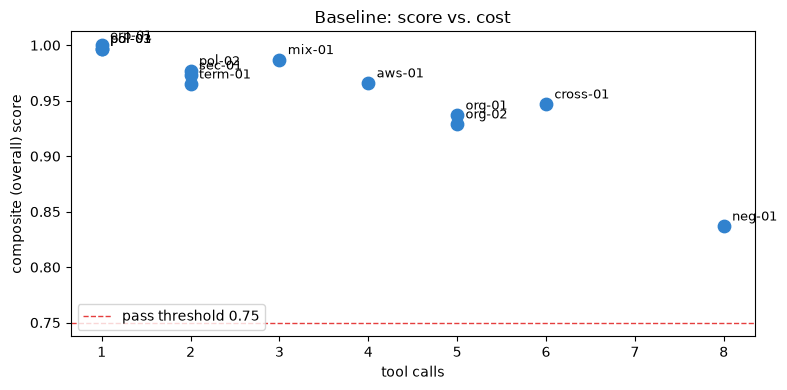

In [9]:
import matplotlib.pyplot as plt

df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["tool_calls"], df["composite"], s=80, color="#3182ce")
for _, r in df.iterrows():
    ax.annotate(r["id"], (r["tool_calls"], r["composite"]), textcoords="offset points", xytext=(6, 4), fontsize=9)
ax.axhline(0.75, color="#e53e3e", linestyle="--", linewidth=1, label="pass threshold 0.75")
ax.set_xlabel("tool calls")
ax.set_ylabel("composite (overall) score")
ax.set_title("Baseline: score vs. cost")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

### 💡 점수만 보면 놓치는 것

통과 기준(`0.75`)만 보면 12문항 모두 합격일 수 있습니다. 그런데 산점도에서 **오른쪽(도구 호출 많음)이나 아래쪽(점수 낮음)으로 떨어진 점**을 주목해야 합니다.
정답은 맞혔더라도 과정이 비효율적이어서 **응답 지연 시간과 토큰 비용이 다른 문항의 몇 배**에 달하는 병목 지점이기 때문입니다. (LLM 실행이므로 세부 수치는 실행할 때마다 조금씩 달라집니다.)

---
## 🔍 Part 5. 실패 진단에서 하네스 개선·비회귀 검증까지

### 5.1 궤적 분석과 원인 계층 귀속 (`neg-01`)

Part 4의 산점도에서 오른쪽으로 크게 벗어난 **`neg-01` (존재하지 않는 상여금 질문)**을 진단해 봅니다.
정답이 *"확인되지 않는다"*이므로 결과 점수는 만점에 가깝지만, 그 결론을 내리기까지 검색을 반복하며 `비효율 호출` 진단을 받았습니다. 실제 도구 호출 궤적(`trajectory`)을 열어 **어떤 도구에 어떤 검색어를 넣었고 무엇을 돌려받았는지** 확인합니다.

In [10]:
from app.eval.rag_eval import run_case


def show_trajectory(record: dict, width: int = 100):
    # 도구 결과의 첫 줄(출처 머리글 또는 상태 신호)만 출력해 어떤 문맥을 돌려받았는지 확인합니다.
    for i, step in enumerate(record["trajectory"], 1):
        print(f"Step {i:>2}: {step['tool_name']}({step['arguments']})")
        head = (step["response_snippet"].strip().splitlines() or ["(빈 결과)"])[0]
        print(f"         ↳ {head[:width]}")


case = next(c for c in golden if c["id"] == "neg-01")
base = next(r for r in rows if r["id"] == "neg-01")
print(f"🎯 진단 대상: {case['id']} | {case['question']}")
print(f"   베이스라인: 종합 {base['composite']:.2f} (과정 {base['trajectory']:.2f}, 호출 효율 {base['step_economy']:.2f}, 정답 일치 {base['correctness']:.2f}) | 도구 호출 {base['tool_calls']}회")
print(f"   진단: {', '.join(base['diagnoses']) or '-'}")
print(f"   과정 채점기 의견: {base['critique']}\n")

record = await run_case(agent, case)
show_trajectory(record)
print(f"\n⏱️ {record['duration_s']}s | 도구 호출 {len(record['trajectory'])}회")
print("💬 최종 답변:\n" + record["answer"][:650])

🎯 진단 대상: neg-01 | 2026년에 신설된 우주항공 특별 연구 상여금의 지급 기준과 금액은 얼마인가요?
   베이스라인: 종합 0.84 (과정 0.62, 호출 효율 0.40, 정답 일치 1.00) | 도구 호출 8회
   진단: 비효율 호출
   과정 채점기 의견: 권장 도구인 search_company_policy를 사용해 사내 규정에서 해당 제도 유무와 유사한 보상 규정을 찾으려 했고, 이후 우주항공/상여금/특례 규정처럼 키워드를 바꿔 추가 탐색했습니다. 다만 graph_find_entities와 search_enterprise_erp는 질문의 핵심(정책상 지급 기준·금액 확인)과 직접적 관련성이 낮아 다소 헛도는 탐색이 있었고, 같은 정보를 다른 각도에서 반복 확인한 흔적이 있습니다.



Step  1: search_company_policy({'query': '우주항공 특별 연구 상여금'})
         ↳ [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 5] 2026년 1분기 전사 GPU 클러스터 할당 및 가동률 관제 현황표 (제5조, 제10조, 제12조 
Step  2: search_company_policy({'query': '우주항공'})
         ↳ [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 7] 멀티리전 재해복구(DR) 분기별 모의훈련 시나리오 및 합격 기준 (제14조~제16조 관련)]:
Step  3: graph_find_entities({'query': '우주항공'})
         ↳ ### '우주항공' 관련 엔티티 5개 (유사도 순)
Step  4: search_enterprise_erp({'query': '우주항공 관련 프로젝트나 상여금 내역이 있나요?'})
         ↳ [status: ok]
Step  5: search_company_policy({'query': '상여금'})
         ↳ [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 7] 멀티리전 재해복구(DR) 분기별 모의훈련 시나리오 및 합격 기준 (제14조~제16조 관련)]:
Step  6: search_enterprise_erp({'query': 'ERP에 존재하는 테이블 목록과 스키마 구조를 보여주세요.'})
         ↳ [status: ok]
Step  7: search_company_policy({'query': '연구'})
         ↳ [(주)넥스트AI 클라우드 및 GPU 인프라 운영 지침 > 부칙 > [별표 5] 2026년 1분기 전사 GPU 클러스터 할당 및 가동률 관제 현황표 (제5조, 제10조, 제12조 
Step  8: search_company_policy({'query': '특별'})
         ↳ [(주)넥스

### 🧠 계층 귀속(Layer Attribution): 무엇이 진짜 원인인가?

궤적을 보면 에이전트가 왜 멈추지 못했는지 명확히 드러납니다.
- **결과만 채점했다면 놓쳤을 결함:** 최종 답변은 없는 제도를 지어내지 않고 정확히 답했습니다(`정답 일치 ≈ 1.0`).
- **무조건 상위 2개를 돌려주는 도구 반환 형식:** `search_company_policy`는 질문과 아무 관련이 없는 검색어(`"우주항공 특별 연구 상여금"`, `"우주"`)를 넣어도 **항상 상위 청크 2개(GPU 운영 지침 별표, 재해복구 훈련 별표 등)를 반환**합니다. 에이전트 입장에서는 *"사내 규정에 해당 제도가 아예 없는 것"*인지 *"내 검색어가 나빠서 다른 조항이 걸린 것"*인지 구분할 신호가 없습니다.
- **타 저장소까지 번지는 연쇄 탐색:** 규정 도구에서 "없다"는 확신을 얻지 못하니 ERP와 지식 그래프까지 전수 조사하듯 뒤진 끝에야 결론을 내립니다.

| 원인 후보 계층 | 판단 및 근거 |
|:---|:---|
| **인덱스 계층** | 5대 사내 규정은 정상 색인되어 있고, 실제로 없는 제도이므로 관련 청크가 없는 것이 정상 → **원인 아님** |
| **시스템 프롬프트** | *"근거가 없으면 확인되지 않는다고 답하라"*는 원칙은 있으나, **언제 재검색을 멈출지** 기준이 없음 → **보조 원인** |
| **도구 반환 계약 (주원인)** | 관련도와 무관하게 무조건 top-2 청크만 반환하고, **`[관련 조항 없음]` 신호와 검색 대상 범위(5대 규정 목록)**를 알려주지 않음 → **핵심 원인 ✅** |

### 5.2 [실습] 하네스 계층 수정(`agent_v2`)과 전체 골든셋 비회귀 검증(`compare_table`)

진단 결과를 바탕으로 **모델(`gemini-3.8-flash`)은 그대로 둔 채 에이전트 하네스의 두 지점**만 정교하게 수정해 `agent_v2`를 만듭니다.

1. **도구 반환 계약 개선 (`search_company_policy_v2`):**
   - 벡터 검색의 최근접 L2 거리(`best_dist`)가 임계값(`MAX_L2_DISTANCE = 1.20`)을 넘으면 무관한 청크를 억지로 반환하는 대신 **`"[관련 조항 없음] ... 검색 완료 범위(5대 사내 규정): 국내여비교통비지급규정, 인사복무규정, ..."`**을 명시적으로 돌려줍니다.
   - **임계값 설계 주의점:** 임계값을 너무 좁게(예: `0.80`) 잡으면 `term-01`(*"과장급 직원 당일 출장 일비"*, 거리 약 `0.88~1.10`)처럼 질문 어휘와 문서 어휘가 다른 정상 문항까지 차단되어 **회귀(Regression)**가 발생합니다. 사내 정상 질의 분포(`0.56~1.10`)와 미존재 질의 분포(`1.23~1.56`) 사이인 `1.20`으로 설정합니다.
2. **프롬프트 중단 규칙 추가 (`TOOL_RAG_SYSTEM_PROMPT_V2`):**
   - 도구가 `[관련 조항 없음]`과 검색 완료 범위를 반환하면, 상위 일반 개념(예: 포상·성과급)으로 최대 1~2회만 보충 확인한 뒤에도 없을 경우 다른 DB(ERP·그래프)를 전수 탐색하지 않고 즉시 결론을 내리도록 명시합니다.

먼저 수정된 `agent_v2`로 `neg-01`의 궤적이 어떻게 달라졌는지 확인한 뒤, **12문항 전체를 재평가하여 `compare_table`로 개선과 비회귀 여부를 검증**합니다.

In [11]:
from langchain_core.tools import tool

MAX_L2_DISTANCE = 1.20
POLICY_SCOPE = (
    "국내여비교통비지급규정, 인사복무규정, 정보보안관리지침, "
    "전사위임전결및예산집행규정, 클라우드및GPU인프라운영지침"
)


@tool("search_company_policy")
def search_company_policy_v2(query: str) -> str:
    """
    사내 5대 공식 규정 문서(국내여비교통비지급규정, 인사복무규정, 정보보안관리지침, 전사위임전결및예산집행규정, 클라우드및GPU인프라운영지침)에서 출장비 기준, 인사·징계 양정, 보안 반출 절차, 금액별 전결 기준, GPU 유휴 회수 규정 등 사내 제도·원칙 조항을 검색합니다.

    반환 형태: 검색된 조항의 앞뒤 문맥이 결합된 본문과 함께 상단에 [문서 전체 목차(TOC)] 및 [현재 위치 경로(Breadcrumb)]가 포함된 텍스트를 반환합니다. 관련도가 기준 미만이면 [관련 조항 없음]과 검색 완료 범위를 반환합니다.
    """
    retriever = T._policy_retriever()
    norm_q = retriever.domain_dict.normalize(query)
    scored = retriever.vectorstore.similarity_search_with_score(norm_q, k=1)
    best_dist = scored[0][1] if scored else 999.0
    if best_dist > MAX_L2_DISTANCE:
        return (
            f"[관련 조항 없음] '{query}'와 직접 일치하는 사내 규정 조항이 없습니다 "
            f"(최근접 거리={best_dist:.2f} > 기준 {MAX_L2_DISTANCE:.2f}).\n"
            f"- 검색 완료 범위(5대 사내 규정): {POLICY_SCOPE}"
        )
    docs = retriever.search(query, top_k=2)
    return "\n\n".join(f"[{d.metadata.get('breadcrumb', '사내규정')}]:\n{d.page_content}" for d in docs)


TOOL_RAG_SYSTEM_PROMPT_V2 = TOOL_RAG_SYSTEM_PROMPT + (
    "\n5. 도구가 '[관련 조항 없음]'과 검색 완료 범위를 반환하면, 상위 일반 개념(예: 포상·성과급 등)으로 최대 1~2회만 "
    "보충 확인한 뒤에도 해당 제도가 없으면 다른 DB를 전수 탐색하지 말고 즉시 '확인되지 않는다'고 답변하세요.\n"
)

tools_v2 = [search_company_policy_v2 if t.name == "search_company_policy" else t for t in T.tools_tool_rag]
agent_v2 = create_agent(model=llm, tools=tools_v2, system_prompt=TOOL_RAG_SYSTEM_PROMPT_V2, checkpointer=InMemorySaver())

print("🔧 [agent_v2] neg-01 재실행 궤적 확인:\n")
record_v2 = await run_case(agent_v2, case)
show_trajectory(record_v2)
print(f"\n⏱️ 개선 전 {record['duration_s']}s ({len(record['trajectory'])}회 호출)  ──▶  개선 후 {record_v2['duration_s']}s ({len(record_v2['trajectory'])}회 호출)")

🔧 [agent_v2] neg-01 재실행 궤적 확인:



Step  1: search_company_policy({'query': '우주항공 특별 연구 상여금 지급 기준 금액'})
         ↳ [(주)넥스트AI 인사 및 복무 관리 규정 > 제4장 인사 평가 및 승진·보상 > 제21조 (승진 연한 및 특별 승진 심사)]:
Step  2: search_company_policy({'query': '우주항공'})
         ↳ [관련 조항 없음] '우주항공'와 직접 일치하는 사내 규정 조항이 없습니다 (최근접 거리=1.48 > 기준 1.20).

⏱️ 개선 전 71.1s (10회 호출)  ──▶  개선 후 16.9s (2회 호출)


In [12]:
from app.eval.rag_eval import compare_table

print("🧪 개선 에이전트(agent_v2) 골든셋 12문항 전체 재평가 (비회귀 검증)\n")
rows_v2 = await evaluate_agent(agent_v2, golden, judge_llm=judge_llm, concurrency=4)

print("\n📊 [Before (v1)] " + summary_line(rows))
print("📊 [After  (v2)] " + summary_line(rows_v2))

comp_df = compare_table(rows, rows_v2)
display(comp_df.style.format({"종합 (전)": "{:.2f}", "종합 (후)": "{:.2f}", "변화": "{:+.2f}", "소요(s) (전)": "{:.1f}", "소요(s) (후)": "{:.1f}"}).hide(axis="index"))

🧪 개선 에이전트(agent_v2) 골든셋 12문항 전체 재평가 (비회귀 검증)



  ✔ pol-03   종합 0.99 (통과) | 도구 호출 1회


  ✔ pol-01   종합 0.99 (통과) | 도구 호출 1회


  ✔ sec-01   종합 1.00 (통과) | 도구 호출 2회


  ✔ pol-02   종합 0.99 (통과) | 도구 호출 3회


  ✔ aws-01   종합 0.97 (통과) | 도구 호출 4회


... (4 outputs left out)

  ✔ neg-01   종합 0.97 (통과) | 도구 호출 2회


  ✔ mix-01   종합 0.92 (통과) | 도구 호출 4회


  ✔ cross-01 종합 0.99 (통과) | 도구 호출 4회

📊 [Before (v1)] 평균 종합 점수 0.959 | 통과 12/12 (기준 0.75) | 평균 도구 호출 3.3회 | 평균 소요 35.9s
📊 [After  (v2)] 평균 종합 점수 0.974 | 통과 12/12 (기준 0.75) | 평균 도구 호출 3.0회 | 평균 소요 29.2s


문항,종합 (전),종합 (후),변화,호출 수 (전),호출 수 (후),소요(s) (전),소요(s) (후),판정
aws-01,0.97,0.97,+0.00,4,4,32.0,26.5,유지
cross-01,0.95,0.99,+0.05,6,4,85.7,64.9,유지
erp-01,1.00,0.99,-0.01,1,2,20.7,37.4,유지
mix-01,0.99,0.92,-0.06,3,4,26.8,36.0,유지
neg-01,0.84,0.97,+0.14,8,2,83.0,15.7,개선
org-01,0.94,0.93,-0.01,5,6,25.1,39.0,유지
org-02,0.93,0.99,+0.06,5,4,47.9,40.3,유지
pol-01,1.00,0.99,-0.01,1,1,16.3,9.3,유지
pol-02,0.98,0.99,+0.02,2,3,34.6,30.0,유지
pol-03,1.00,0.99,-0.00,1,1,15.8,7.3,유지


### ✅ 비회귀 검증(`compare_table`) 읽는 법

- **`neg-01` 병목 해소:** 도구가 `[관련 조항 없음]`과 5대 규정 검색 범위를 명확히 돌려주자, 에이전트가 불필요하게 ERP·지식 그래프까지 뒤지지 않고 2~3회 내에 탐색을 마무리해 **호출 수와 응답 시간이 대폭 단축**되고 과정 점수가 회복되었습니다.
- **타 문항 비회귀(`회귀 ⚠️` 0건) 확인:** `term-01`(*"과장급"*), `pol-01~03`, `cross-01` 등 기존 통과 문항들의 종합 점수 변화가 모두 흔들림 허용폭(`rag_eval.NOISE_BAND = ±0.10`) 안쪽에 머물거나 유지되어, 새 임계값(`1.20`)과 중단 규칙이 정상 검색을 방해하지 않음을 숫자로 증명했습니다.

---
## 🏭 Part 6. 운영 관점: 무엇을 실시간으로, 무엇을 오프라인으로

### 6.1 실행 중 개입: 자동 크로스체크와 사람(HITL)

평가 하네스는 실행이 **끝난 뒤** 시스템을 고칩니다. 반대로 실행 **도중**에 개입하는 장치도 있습니다. Part 1의 "실행 중 자가 수정"에 해당합니다.

| 방식 | 하는 일 | 언제 쓰나 |
|:---|:---|:---|
| **자동 크로스체크** (판사 모델) | 최종 답변을 내기 직전에 다른 모델이 궤적과 답변을 검사하고, 결함이 있으면 피드백과 함께 재작업을 지시 | 매 요청에 지연과 비용이 붙으므로, 틀리면 대가가 큰 **중요한 작업에만** |
| **사람의 개입 (Human-in-the-Loop)** | 에이전트를 멈추고 사람이 승인·수정·거절 | 에이전트가 스스로 판단해 **비싸거나 위험한 일**을 하려 할 때 |

검색 결과가 부실할 때 다시 찾는 일은 ReAct 루프 안에서 모델이 이미 합니다. 그래서 자동 장치는 "재검색"보다 **"답변 확정 전 검사"**에 두는 것이 효과적입니다.

### 6.2 런타임 크로스체크: 판사 모델이 답변을 반려하고 재작업시키기 (StopHook 패턴)

에이전트가 도구 호출 루프(`model` ↔ `tools`)를 마치고 최종 답변을 내보내려 할 때(`after_agent` / StopHook 지점), 미들웨어가 지금까지의 궤적과 최종 답변을 **다른 모델(판사)**에게 보여 줍니다.
판사가 반려하면 수정 피드백을 `HumanMessage`로 대화에 주입하고 `jump_to="model"`을 반환해 `END` 대신 `model` 노드로 되돌려 답변을 다시 쓰게 합니다. Part 3의 오프라인 채점기를 **에이전트 종료 직전(`after_agent`)으로 옮겨 온 인루프 자가 교정(Self-Correction) 구조**입니다.

```mermaid
flowchart LR
    subgraph ReAct["🔄 ReAct 루프"]
        M["🤖 model<br/>답변 또는 도구 호출"] -->|"tool_calls 있음"| X["⚡ tools<br/>도구 실행"]
        X --> M
    end
    M -->|"tool_calls 없음<br/>(최종 답변)"| H["🛑 after_agent (StopHook)<br/>@hook_config(can_jump_to=['model'])"]
    H --> J{"⚖️ 판사 모델 검증<br/>(궤적 + 최종 답변)"}
    J -->|"승인 (또는 max_reworks 도달)<br/>return None"| E["🏁 END<br/>(사용자에게 응답)"]
    J -->|"반려: 피드백 HumanMessage 주입<br/>+ jump_to='model' (Self-Repair Loop)"| M
```

> 💡 **왜 `after_agent`에 `@hook_config(can_jump_to=["model"])`를 선언하나요?**
> - `create_agent`의 기본 그래프는 도구 호출이 끝나면 `model → after_agent → END`로 곧장 종료됩니다.
> - `after_agent` 훅에 `@hook_config(can_jump_to=["model"])` 데코레이터를 선언해야만 그래프에 `after_agent → model` 조건부 복귀 엣지가 열리며, 검증 실패 시 `{"messages": [feedback], "jump_to": "model"}`을 반환해 모델을 다시 깨울 수 있습니다.

핵심 구현만 추리면 다음과 같습니다. (이 노트북에서는 실행하지 않습니다.)

```python
from langchain.agents.middleware import AgentMiddleware, hook_config
from langchain_core.messages import AIMessage, HumanMessage


class AnswerCrossCheck(AgentMiddleware):
    def __init__(self, judge, max_reworks: int = 2):
        self.judge, self.max_reworks = judge, max_reworks   # judge: 궤적 → {approved, feedback}

    @hook_config(can_jump_to=["model"])
    def after_agent(self, state, runtime):
        messages = state.get("messages", [])
        if not messages or not isinstance(messages[-1], AIMessage):
            return None
        # 재작업 횟수는 대화 안의 검토 의견(cross_check) 수로 셉니다 (max_reworks 도달 시 무한 루프 방지)
        reworks = sum(getattr(m, "name", None) == "cross_check" for m in messages)
        verdict = self.judge(messages)       # 질문, 도구 결과, 최종 답변을 판사에게 전달
        if verdict.approved or reworks >= self.max_reworks:
            return None                      # 검증 통과 또는 재시도 한도 도달 → END로 정상 종료
        feedback = HumanMessage(
            content=f"[검토 의견] {verdict.feedback}\n위 의견을 반영해 답변을 다시 작성하세요.",
            name="cross_check",
        )
        return {"messages": [feedback], "jump_to": "model"}  # 피드백 주입 후 model 노드로 복귀
```

**판사가 잡을 수 있는 것과 없는 것**

런타임 판사에게는 **정답 라벨이 없습니다.** 그래서 오프라인 채점기와 같은 일을 할 수는 없고, 질문·도구 결과·답변 사이의 어긋남만 볼 수 있습니다.

| 잡을 수 있음 | 잡을 수 없음 |
|:---|:---|
| 질문의 요구사항 중 빠진 것 (예: "결재자와 정산 기한" 중 기한 누락) | 사실 자체가 맞는지 (정답 라벨이 없음, Part 3의 정답 일치는 오프라인에서만) |
| 답변의 수치·조항이 도구 결과와 다름 (전결 금액을 잘못 옮김) | 검색에서 아예 빠진 근거 (도구 결과에 없으면 판사도 모름) |
| 도구 결과에 없는 내용을 단정함 (없는 제도를 지어냄) | |

**적용 원칙**

| 원칙 | 이유 |
|:---|:---|
| **대상을 좁힙니다.** ERP 수치, 전결·예산 기준처럼 틀리면 대가가 큰 답변에만 판사를 실행 | 모든 답변에 붙이면 매 요청 LLM 호출이 1회 이상 늘고, 반려되면 답변 생성이 한 번 더 일어남 |
| 판사는 에이전트와 **다른 계열 모델** | 같은 모델이 자기 답을 후하게 보는 편향 (Part 3과 같은 이유) |
| 반려 기준은 **치명적 결함**으로 한정 | 문체나 사소한 표현까지 반려하면 재작업만 늘고 품질은 그대로 |
| **재작업 한도** (1~2회) | 판사와 에이전트의 판단이 계속 엇갈리면 무한 루프 |
| 판정 실패는 통과시키되 **기록** | 판사 오류가 사용자 응답을 막지 않게 하되, 반려율 통계는 왜곡되지 않게 |
| 피드백은 **구체적으로** (빠진 요구사항, 다시 볼 도구 결과) | "다시 해 보세요"만으로는 같은 답이 다시 나옴 |

> 💡 **실무 팁:** **붙일지 말지는 평가 하네스로 정합니다.** 같은 골든셋으로 "베이스라인"과 "베이스라인 + 크로스체크"를 채점해 **점수가 오른 폭**과 **늘어난 소요 시간·재작업 횟수**를 비교합니다.

### 6.3 사람의 개입: 운영 DB 조회 앞에 승인 게이트 두기

단순 검색-답변 RAG에서는 HITL의 비중이 크지 않습니다. 읽기만 하므로 잘못돼도 틀린 답변 하나로 끝나기 때문입니다.
**RAG가 에이전트가 되면서** 에이전트가 스스로 도구를 고르고 반복 호출하므로, 사람이 개입할 지점이 생깁니다.

| 개입 지점 | 왜 필요한가 | 이 과정의 예 |
|:---|:---|:---|
| **① 비싸거나 위험한 도구 호출 전 승인** | 자율성을 주면 비용과 위험을 통제할 장치가 필요 | Text2SQL의 실제 DB 실행, 대외비 레코드 조회, 상태를 바꾸는 도구(예산 전용 신청 등) |
| **② 답변 확정 전 검토** | 틀린 답의 대가가 큰 도메인 | 근거 점수가 낮은 답변을 담당자 검토 대기열로 |
| **③ 질문 명확화** | 추측하며 검색을 반복하는 것보다 되묻는 것이 싸고 정확 | `term-01` "과장급": 규정에 없는 직급 → 반복 검색 대신 확인 질문 |
| **④ 피드백 → 평가 루프** | 사람의 판정이 골든셋으로 쌓여야 평가가 계속 자람 | 6.4의 "운영 중 실패·반려 → 골든셋 추가" |

#### 실습

LangChain의 `HumanInTheLoopMiddleware`를 `create_agent`에 붙이면, 지정한 도구를 호출하기 **직전에 실행이 멈춥니다(interrupt)**.
사람이 결정을 내려 주면 **체크포인터에 저장된 상태에서 그대로 재개(resume)**합니다. 앞서 에이전트에 붙인 체크포인터가 여기서 필요한 이유입니다.

이번에는 `search_enterprise_erp`를 승인 대상으로 삼습니다. 이 도구는 LLM이 만든 SQL을 **운영 ERP DB에 실제로 실행**하고, 결과에는 지출 전표·임직원 명부 같은 대외비 레코드가 들어 있을 수 있습니다. 나머지 도구는 미리 만들어 둔 인덱스(벡터 DB, 지식 그래프)를 읽기만 합니다.

| 도구 호출 | 정책 (`interrupt_on`) | 이유 |
|:---|:---|:---|
| `search_company_policy`, `search_aws_guides` | 자동 실행 | 미리 만든 문서 인덱스를 읽는 검색 |
| `graph_*` 탐색 도구 5종 | 자동 실행 | 미리 만든 지식 그래프 인덱스를 읽는 조회 (LLM 호출 없음) |
| `search_enterprise_erp` | **승인 필요** (`approve` / `edit` / `reject`) | LLM이 생성한 SQL을 운영 DB에 실행, 대외비 레코드를 반환할 수 있음 |

> 💡 같은 도구라도 인자에 따라 정책을 다르게 하려면 `interrupt_on`에 **`when` 조건 함수**를 넣습니다. 예를 들어 질의에 "전표"나 "명부"가 들어 있을 때만 멈추게 할 수 있습니다.

```mermaid
flowchart LR
    A["🤖 에이전트<br/>도구 호출 제안"] --> G{"🛑 HITL 정책<br/>ERP 조회인가?"}
    G -->|"그 외 호출"| R["⚡ 즉시 실행"]
    G -->|"search_enterprise_erp"| I["⏸️ interrupt<br/>체크포인터에 상태 저장"]
    I --> H{"👤 사람"}
    H -->|"approve"| R
    H -->|"edit: 조회 범위를 집계로 축소"| R
    H -->|"reject + 사유·대안"| F["❌ 실행 안 함<br/>사유를 에이전트에 전달"]
    R --> A
    F --> A
```

In [13]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.types import Command


hitl_agent = create_agent(
    model=llm,
    tools=tools_v2,
    system_prompt=TOOL_RAG_SYSTEM_PROMPT_V2,
    checkpointer=InMemorySaver(),   # 멈춘 상태를 저장해 두어야 재개할 수 있음
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                # 운영 DB에 SQL을 실행하는 ERP 조회만 멈춥니다. 나머지 도구는 자동 실행
                "search_enterprise_erp": {"allowed_decisions": ["approve", "edit", "reject"]},
            },
            description_prefix="🛑 ERP 조회는 운영 DB에 SQL을 실행하므로 승인이 필요합니다.",
        )
    ],
)


def show_pending(result) -> bool:
    """멈춘 실행이 있으면 승인 대기 중인 도구 호출을 보여 줍니다."""
    if "__interrupt__" not in result:
        return False
    request = result["__interrupt__"][0].value
    for action, review in zip(request["action_requests"], request["review_configs"]):
        print(f"⏸️ 승인 대기: {action['name']}({action['args']})")
        print(f"   허용된 결정: {review['allowed_decisions']}")
    return True


def resume(agent, result, decide, config: dict):
    """대기 중인 도구 호출마다 결정을 내려 재개합니다. (병렬 호출이면 승인 요청도 여러 건)

    decide: 모든 호출에 같은 결정을 내릴 때는 dict, 호출 내용을 보고 결정할 때는 action -> dict 함수
    """
    pending = result["__interrupt__"][0].value["action_requests"]
    decisions = [decide(action) if callable(decide) else decide for action in pending]
    return agent.invoke(Command(resume={"decisions": decisions}), config=config)


def show_answer(result):
    used = [tc["name"] for m in result["messages"] for tc in (getattr(m, "tool_calls", None) or [])]
    print(f"🔧 사용한 도구: {used}")
    print("💬 최종 답변:\n" + normalize_content(result["messages"][-1].content)[:700])


print("✅ HITL 에이전트 준비 완료: search_enterprise_erp 호출 전 승인 필요")

✅ HITL 에이전트 준비 완료: search_enterprise_erp 호출 전 승인 필요


**시나리오 A: 승인 (approve)**

ERP에만 있는 수치(승인완료 지출 합계)를 물으면 에이전트는 `search_enterprise_erp`를 고릅니다. 실행은 도구 호출 직전에 멈춥니다.

In [14]:
config_a = {"configurable": {"thread_id": "hitl-approve"}}
question_a = "P-05 프로젝트에서 승인완료된 지출 합계는 얼마인가요?"

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_a}]}, config=config_a)
paused = show_pending(result)
print("\n📌 실행이 멈췄는가?", paused)

⏸️ 승인 대기: search_enterprise_erp({'context': 'P-05 프로젝트의 지출 결의 내역 및 승인완료 상태의 지출 합계', 'query': 'P-05 프로젝트에서 승인완료된 지출 결의 전표의 금액 합계는 얼마인가요?'})
   허용된 결정: ['approve', 'edit', 'reject']

📌 실행이 멈췄는가? True


In [15]:
# 사람이 내용을 확인하고 승인하면, 저장된 상태에서 이어서 실행됩니다.
while "__interrupt__" in result:
    result = resume(hitl_agent, result, {"type": "approve"}, config_a)

show_answer(result)

🔧 사용한 도구: ['search_enterprise_erp', 'search_enterprise_erp']
💬 최종 답변:
사내 ERP 정형 데이터베이스(프로젝트 지출 결의 전표)를 조회한 결과는 다음과 같습니다.

### **P-05 프로젝트 승인완료 지출 현황**

- **프로젝트 코드:** P-05
- **프로젝트명:** 멀티클라우드 GPU 추론 클러스터 고도화
- **승인완료 건수:** 총 26건
- **승인완료 지출 합계:** **527,000,000원 (5억 2,700만 원)**

---

#### **비목별 세부 승인 합계**
1. **GPU 클러스터 임차 (3건):** 355,000,000원
   - kr-central-1 리전 H100 8-GPU 베어메탈 노드 장기 임차 (1차): 125,000,000원
   - ap-northeast-2 리전 H100 클러스터 증설 임차 (2차): 118,000,000원
   - A100/L40S 하이브리드 추론 노드 임차 (3차): 112,000,000원
2. **외주용역 (2건):** 126,000,000원
   - InfiniBand 400Gbps RDMA 패브릭 네트워크 구축 및 튜닝: 74,000,000원
   - GPU KV-Cache 및 가동률 관제 시스템 구축: 52,000,000원
3. **보안감사 (1건):** 19,000,000원
   - GPU 컨테이너 런타임 격리 및 이미지 서명 보안 감사
4. **해외출장 (1건):** 16,500,000원
   - NVIDIA GTC 2026 


**시나리오 B: 수정 후 실행 (edit)**

"지출 현황"처럼 범위가 넓은 질문에 에이전트는 개별 지출 전표까지 나올 수 있는 넓은 조회를 시도하곤 합니다. 사람은 거절 대신 **인자를 고쳐서** 실행할 수 있습니다.
여기서는 첫 ERP 조회를 **프로젝트별 집계**로 좁히고(데이터 최소화), 이후 조회는 승인합니다.
에이전트는 인자가 수정된 사실을 따로 통보받지 않고 수정된 호출의 결과만 받으므로, 수정한 결과로도 질문에 답할 수 있게 고쳐야 합니다.

In [16]:
config_b = {"configurable": {"thread_id": "hitl-edit"}}
question_b = "AgenticAI팀 프로젝트들의 지출 현황을 알려줘."

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_b}]}, config=config_b)


def narrow_to_summary(action: dict) -> dict:
    """개별 전표 행이 나오지 않도록 질의와 참고 맥락을 프로젝트별 집계로 고칩니다."""
    edited = {"query": "AgenticAI팀 프로젝트별 승인완료 지출 건수와 합계", "context": "개별 전표 행은 조회하지 않음"}
    print(f"✏️ 수정: {action['args']['query']}\n   → {edited['query']}\n")
    return {"type": "edit", "edited_action": {"name": action["name"], "args": edited}}


edited = False
while show_pending(result):
    # 첫 조회는 범위를 좁혀 실행하고, 이후 조회는 승인합니다.
    decide = {"type": "approve"} if edited else narrow_to_summary
    result = resume(hitl_agent, result, decide, config_b)
    edited = True

if not edited:
    print("ℹ️ 이번 실행에서는 에이전트가 ERP를 조회하지 않아 승인 요청이 없었습니다. (다시 실행하면 달라질 수 있습니다)\n")
show_answer(result)

⏸️ 승인 대기: search_enterprise_erp({'context': 'AgenticAI팀의 프로젝트 지출 현황', 'query': 'AgenticAI팀이 담당하는 프로젝트 목록과 해당 프로젝트들의 예산 및 실제 지출(집행) 금액 현황을 조회해줘'})
   허용된 결정: ['approve', 'edit', 'reject']
✏️ 수정: AgenticAI팀이 담당하는 프로젝트 목록과 해당 프로젝트들의 예산 및 실제 지출(집행) 금액 현황을 조회해줘
   → AgenticAI팀 프로젝트별 승인완료 지출 건수와 합계



⏸️ 승인 대기: search_enterprise_erp({'query': 'AgenticAI팀이 주관하는 프로젝트별(P-02, P-04) 총 배정 예산, 집행액, 잔여 예산 및 지출 결의 상태별(승인, 대기 등) 금액 현황', 'context': '프로젝트 전체 예산, 지출 상태별(승인완료, 반려, 대기 등) 금액 및 집행률 확인'})
   허용된 결정: ['approve', 'edit', 'reject']


⏸️ 승인 대기: search_enterprise_erp({'query': 'AgenticAI팀 프로젝트(P-02, P-04)의 비목별 승인완료 지출 금액 현황', 'context': '비목별 승인 지출 내역'})
   허용된 결정: ['approve', 'edit', 'reject']


🔧 사용한 도구: ['graph_find_entities', 'search_enterprise_erp', 'search_enterprise_erp', 'search_enterprise_erp']
💬 최종 답변:
사내 ERP 데이터베이스 조회 결과에 따른 **AgenticAI팀 주관 프로젝트의 예산 및 지출 현황**(2026년 11월 15일 기준)은 다음과 같습니다.

---

### 1. 프로젝트별 예산 및 집행 요약

| 프로젝트 코드 | 프로젝트명 | 총 배정 예산 | 실집행액 (승인완료) | 잔여 예산 | 집행률 | 결재대기 | 반려 |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: |
| **P-02** | 엔터프라이즈 Agentic RAG 플랫폼 구축 | 480,000,000원 | 412,800,000원 (25건) | 67,200,000원 | 86.0% | 65,400,000원 | 5,200,000원 |
| **P-04** | 금융권 생성형 AI 보안 가드레일 구축 | 180,000,000원 | 117,000,000원 (16건) | 63,000,000원 | 65.0% | 18,000,000원 | 115,000원 |
| **합계** | **2개 프로젝트** | **660,000,000원** | **529,800,000원 (41건)** | **130,200,000원** | **80.3%** | **83,400,000원** | **5,315,000원** |

---

### 2. 프로젝트별 세부 비목 지출 현황 (승인완료 기준)

#### ① P-02: 엔터프라이즈 Agen


**시나리오 C: 거절 (reject) + 사유와 대안 전달**

프로젝트의 예산과 승인권자는 지식 그래프에도 있어 운영 DB를 조회할 필요가 없습니다. 그래서 거절하고, **대신 무엇을 하라고** 사유에 적어 보냅니다.
에이전트는 사유를 읽고 그래프 탐색 도구로 답을 찾습니다.

In [17]:
config_c = {"configurable": {"thread_id": "hitl-reject"}}
question_c = "ERP에서 P-02 프로젝트의 승인 예산과 승인권자를 조회해줘."

result = hitl_agent.invoke({"messages": [{"role": "user", "content": question_c}]}, config=config_c)

reject_reason = (
    "프로젝트 예산과 승인권자는 지식 그래프에도 있어 운영 DB를 조회할 필요가 없습니다. "
    "graph_find_entities로 P-02를 찾은 뒤 graph_neighbors로 예산과 승인권자를 확인해서 답하세요."
)
rejected = 0
while show_pending(result):
    print(f"🙅 거절: {reject_reason}\n")
    result = resume(hitl_agent, result, {"type": "reject", "message": reject_reason}, config_c)
    rejected += 1

if rejected == 0:
    print("ℹ️ 이번 실행에서는 에이전트가 ERP 조회 없이 답해 승인 요청이 없었습니다. (다시 실행하면 달라질 수 있습니다)\n")
show_answer(result)

⏸️ 승인 대기: search_enterprise_erp({'query': 'P-02 프로젝트의 승인 예산(approved budget)과 승인권자(approver)를 조회해줘', 'context': 'P-02 프로젝트의 승인 예산과 승인권자 조회'})
   허용된 결정: ['approve', 'edit', 'reject']
🙅 거절: 프로젝트 예산과 승인권자는 지식 그래프에도 있어 운영 DB를 조회할 필요가 없습니다. graph_find_entities로 P-02를 찾은 뒤 graph_neighbors로 예산과 승인권자를 확인해서 답하세요.



🔧 사용한 도구: ['search_enterprise_erp', 'graph_find_entities', 'graph_neighbors', 'graph_neighbors', 'graph_read']
💬 최종 답변:
**P-02 프로젝트(엔터프라이즈 Agentic RAG 플랫폼 구축)**의 승인 예산과 승인권자 정보는 다음과 같습니다.

- **프로젝트명**: P-02 (엔터프라이즈 Agentic RAG 플랫폼 구축)
- **승인 예산**: **4억 8,000만 원** (480,000,000원)
- **승인권자**: **송본부장 상무** (전무/상무급 최종 승인)
- **총괄 PM**: 홍팀장 수석

*(출처: 전사 지식 그래프 및 프로젝트 현황 보고서 T16, T27)*


💡 **HITL 핵심 정리**
- 승인 게이트는 **도구(와 인자) 단위 정책**이라 에이전트 코드나 프롬프트를 고치지 않고 붙였다 뗄 수 있습니다.
- 사람의 선택지는 승인·거절만이 아닙니다. **수정(`edit`)**으로 조회 범위를 좁혀 실행하거나, **거절(`reject`) 시 사유와 대안 도구**를 함께 주면 에이전트는 멈추지 않고 우회 경로로 답을 완성합니다.

### 6.4 평가 하네스의 운영 배치와 데이터 플라이휠 (Production Flywheel)

실제 프로덕션에서는 실시간 사용자 응답을 느리게 하지 않기 위해 **온라인 서빙 경로와 비동기 평가·환류 경로를 분리**합니다.

```mermaid
flowchart LR
    U["👤 사용자"] --> A["🤖 Agentic RAG"]
    A -->|"즉시 응답 (지연 0)"| U
    A -.->|"비동기 트레이스 로깅<br/>(LangSmith / Langfuse / JSONL)"| Q["📥 로그 큐 & HITL 기록<br/>· 5~10% 표본 2계층 채점<br/>· 👎 피드백 / HITL edit·reject"]
    Q -->|"저점수·반려 케이스 추출"| S["🥈 Silver 후보 편입<br/>+ SME 한 줄 검수"]
    S --> G["🏆 골든 데이터셋 확장"]
    G --> CI["🚦 배포 전 CI 품질 게이트<br/>python -m app.eval.rag_eval --compare"]
    CI -->|"평균 ≥ 기준 & 회귀 0건"| A
```

| 단계 | 실행 방식 | 핵심 목적 |
|:---|:---|:---|
| **개발 중 (Local)** | 이 노트북, `python -m app.eval.rag_eval` | 병목 문항 궤적 분석 및 하네스 계층 수정 실험 |
| **배포 전 (CI Gate)** | 골든셋 전체 재채점 + `--compare` 리포트 비교 | 평균 통과 기준 충족 및 기존 통과 문항 **비회귀(`회귀 ⚠️` 0건)** 검증 |
| **운영 중 (Async Flywheel)** | 트래픽 5~10% 비동기 샘플 채점 + HITL `edit`/`reject` 수집 | 골든셋에 없던 새로운 현장 실패 유형을 발견해 **Warm-Start 골든 문항으로 환류** |

운영 중 발견한 실패와 사람의 개입 기록(`edit`/`reject`)이 다시 Part 2의 골든셋으로 편입되면서 **데이터 → 평가 → 하네스 개선 → 운영**의 플라이휠이 완성됩니다.

---
## 🏁 Part 7. 정리 및 더 해 보기

| 단계 | 오늘 실습한 내용 | 현업 엔지니어링 적용 포인트 |
|:---|:---|:---|
| **1. 데이터 연결 & 골든셋** | 12문항 실패 분류 체계 해부 + 원천 규정·스키마 기반 **2단계 반자동 합성(`Evolution → Critique`)** | 초기 배포 전에는 원천 문서에서 합성해 SME의 O/X 검수만 받고, 오픈 후에는 관측 로그(`LangSmith`/`Langfuse`) 반려 건을 편입 |
| **2. 실무 메트릭 설계** | **보편 불변 지표**(`Faithfulness` 2단계 질문 격리 NLI) + **시스템 맞춤 지표**(정규식 코드 채점기, G-Eval 이산 루브릭) | 코드로 판정 가능한 출처·예산·형식은 100% Python 채점기로 처리하고, 의미·정책 판단만 이산 루브릭 LLM 판사로 분리 |
| **3. 진단 & 하네스 개선** | `neg-01` 과잉 호출(11~12회) 원인 진단 → **`search_company_policy_v2` 미존재 신호 계약** 도입 → `compare_table` 검증 | 모델을 바꾸거나 프롬프트를 땜질하기 전에 **도구 반환 계약·시맨틱 레이어**를 고치고 전체 골든셋 무회귀를 증명 |
| **4. 런타임 통제** | 판사 모델 크로스체크(`StopHook`) 설계 + 운영 ERP 조회 앞 **HITL 승인 게이트(`approve`/`edit`/`reject`)** | 실시간 개입은 비용·위험이 큰 도구와 고위험 도메인에만 좁게 배치하고 효과는 오프라인 평가 하네스로 검증 |

### 🧩 더 해 보기

오늘 완성한 개선 루프(`진단 → 하네스 수정 → compare_table 재평가`)를 다른 문항과 계층에도 적용해 보세요.

| 문항 / 주제 | 관찰할 것 | 고쳐 볼 에이전트 하네스 계층 (예시) |
|:---|:---|:---|
| `org-01` (다중 홉) | 그래프 탐색 시 몇 번의 호출을 거치는가? `target_tools`에서 ERP 대안을 빼면 진단이 어떻게 달라지는가? | 그래프 도구의 반환 요약 정보 보강 및 **공정한 `"A \| B"` 채점 라벨** 검증 |
| `cross-01` (규정 + ERP) | 규정에서 찾은 직급·지역별 상한액을 `search_enterprise_erp`의 `context` 인자로 정확히 넘기는가? | 도구 Docstring의 `context` 전달 예시 보강, `semantic_layer.yaml` 직급 규칙 정교화 |
| `aws-01` (동일 소스 다회 검색) | 한국어 질의 시 다른 영역 백서의 동명 섹션(`Design principles`)이 섞여 들어오는가? | 인덱스의 `pillar` 메타데이터를 `search_aws_guides`의 선택적 필터 인자로 노출 |
| 런타임 크로스체크 검증 | 6.2의 `AnswerCrossCheck` 미들웨어를 붙여 동일 골든셋을 채점하면 점수와 평균 지연 시간이 얼마나 변하는가? | 판사 실행 조건을 특정 도구 호출 시로 좁혀 비용 대비 품질 상승폭 측정 |